# PCOS-Klassifikation mit Machine Learning

**Seminararbeit Applied Machine Learning**  
Datensatz: *PCOS data* (Kaggle)  
Zielvariable: `PCOS (Y/N)`

**Ziel:** Vorhersage der Zielvariable `PCOS (Y/N)` anhand klinischer und lebensstilbezogener Merkmale

In [1]:
# Standardbibliotheken
from pathlib import Path
import json
import warnings
import platform
from importlib.metadata import version, PackageNotFoundError

# Datenanalyse und Visualisierung
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

# Scikit-learn
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV,
    learning_curve,
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance

# XGBoost
from xgboost import XGBClassifier


warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

# 2. Datenbereinigung und -vorbereitung

In [2]:
# Relative Dateisuche: Notebook und CSV sollen im selben Ordner liegen.
preferred_file = Path('data without infertility _final.csv')

if preferred_file.exists():
    DATA_FILE = preferred_file
else:
    csv_candidates = sorted(Path.cwd().glob('*.csv'))
    if len(csv_candidates) == 1:
        DATA_FILE = csv_candidates[0]
    elif len(csv_candidates) == 0:
        raise FileNotFoundError('Keine CSV-Datei im Notebook-Ordner gefunden.')
    else:
        raise FileNotFoundError(
            'Mehrere CSV-Dateien gefunden. Bitte DATA_FILE oben explizit setzen: '
            + ', '.join(p.name for p in csv_candidates)
        )

raw = pd.read_csv(DATA_FILE)
print(f'Datei: {DATA_FILE.resolve()}')
print(f'Rohdaten: {raw.shape[0]} Zeilen, {raw.shape[1]} Spalten')
display(raw.head())

Datei: /Users/nillab/Sommersemester 2026 Seminararbeit ML & Forecasting/AML _PCOS Data/data without infertility _final.csv
Rohdaten: 541 Zeilen, 43 Spalten


,Sl. No,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),Hb(g/dl),Cycle(R/I),Cycle length(days),Marraige Status (Yrs),Pregnant(Y/N),No. of aborptions,FSH(mIU/mL),LH(mIU/mL),FSH/LH,Hip(inch),Waist(inch),Waist:Hip Ratio,TSH (mIU/L),AMH(ng/mL),PRL(ng/mL),Vit D3 (ng/mL),PRG(ng/mL),RBS(mg/dl),Weight gain(Y/N),hair growth(Y/N),Skin darkening (Y/N),Hair loss(Y/N),Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm),Unnamed: 42
0,1,10001,0,28,44.6000,152.0000,19.3000,15,78,22,10.4800,2,5,7.0000,0,0,7.9500,3.6800,2.1603,36,30,0.8333,0.6800,2.07,45.1600,17.1000,0.5700,92.0000,0,0,0,0,0,1.0000,0,110,80,3,3,18.0000,18.0000,8.5000,NaN
1,2,10002,0,36,65.0000,161.5000,24.9212,15,74,20,11.7000,2,5,11.0000,1,0,6.7300,1.0900,6.1743,38,32,0.8421,3.1600,1.53,20.0900,61.3000,0.9700,92.0000,0,0,0,0,0,0.0000,0,120,70,3,5,15.0000,14.0000,3.7000,NaN
2,3,10003,1,33,68.8000,165.0000,25.2709,11,72,18,11.8000,2,5,10.0000,1,0,5.5400,0.8800,6.2955,40,36,0.9000,2.5400,6.63,10.5200,49.7000,0.3600,84.0000,0,0,0,1,1,1.0000,0,120,80,13,15,18.0000,20.0000,10.0000,NaN
3,4,10004,0,37,65.0000,148.0000,29.6749,13,72,20,12.0000,2,5,4.0000,0,0,8.0600,2.3600,3.4153,42,36,0.8571,16.4100,1.22,36.9000,33.4000,0.3600,76.0000,0,0,0,0,0,0.0000,0,120,70,2,2,15.0000,14.0000,7.5000,NaN
4,5,10005,0,25,52.0000,161.0000,20.0610,11,72,18,10.0000,2,5,1.0000,1,0,3.9800,0.9000,4.4222,37,30,0.8108,3.5700,2.26,30.0900,43.8000,0.3800,84.0000,0,0,0,1,0,0.0000,0,120,80,3,4,16.0000,14.0000,7.0000,NaN


## 2.1 Spaltennamen vereinheitlichen und Datentypen prüfen

In [3]:
RENAME_MAP = {
    'Sl. No': 'Sl_No',
    'Patient File No.': 'Patient_File_No',
    'PCOS (Y/N)': 'PCOS_YN',
    ' Age (yrs)': 'Age_yrs',
    'Weight (Kg)': 'Weight_Kg',
    'Height(Cm) ': 'Height_Cm',
    'BMI': 'BMI',
    'Blood Group': 'Blood_Group',
    'Pulse rate(bpm) ': 'Pulse_rate_bpm',
    'RR (breaths/min)': 'RR_breaths_min',
    'Hb(g/dl)': 'Hb_g_dl',
    'Cycle(R/I)': 'Cycle_R_I',
    'Cycle length(days)': 'Cycle_length_days',
    'Marraige Status (Yrs)': 'Marriage_Status_Yrs',
    'Pregnant(Y/N)': 'Pregnant_YN',
    'No. of aborptions': 'No_of_abortions',
    'FSH(mIU/mL)': 'FSH_mIU_mL',
    'LH(mIU/mL)': 'LH_mIU_mL',
    'FSH/LH': 'FSH_LH_ratio',
    'Hip(inch)': 'Hip_inch',
    'Waist(inch)': 'Waist_inch',
    'Waist:Hip Ratio': 'Waist_Hip_ratio',
    'TSH (mIU/L)': 'TSH_mIU_L',
    'AMH(ng/mL)': 'AMH_ng_mL',
    'PRL(ng/mL)': 'PRL_ng_mL',
    'Vit D3 (ng/mL)': 'Vit_D3_ng_mL',
    'PRG(ng/mL)': 'PRG_ng_mL',
    'RBS(mg/dl)': 'RBS_mg_dl',
    'Weight gain(Y/N)': 'Weight_gain_YN',
    'hair growth(Y/N)': 'Hair_growth_YN',
    'Skin darkening (Y/N)': 'Skin_darkening_YN',
    'Hair loss(Y/N)': 'Hair_loss_YN',
    'Pimples(Y/N)': 'Pimples_YN',
    'Fast food (Y/N)': 'Fast_food_YN',
    'Reg.Exercise(Y/N)': 'Regular_exercise_YN',
    'BP _Systolic (mmHg)': 'BP_systolic_mmHg',
    'BP _Diastolic (mmHg)': 'BP_diastolic_mmHg',
    'Follicle No. (L)': 'Follicle_no_L',
    'Follicle No. (R)': 'Follicle_no_R',
    'Avg. F size (L) (mm)': 'Avg_F_size_L_mm',
    'Avg. F size (R) (mm)': 'Avg_F_size_R_mm',
    'Endometrium (mm)': 'Endometrium_mm',
    'Unnamed: 42': 'Unnamed_42',
}

# Spalten, die schon im Original-Datensatz entfernt werden sollen Beispiel: technische Importspalten wie "Unnamed: 42"
DROP_COLUMNS_RAW = [
    'Unnamed: 42',
]

# Sicherheitsregel: alle Spalten entfernen, die mit "Unnamed" beginnen
AUTO_DROP_UNNAMED = [
    col for col in raw.columns
    if str(col).strip().lower().startswith('unnamed')
]

raw_clean = raw.drop(
    columns=sorted(set(DROP_COLUMNS_RAW + AUTO_DROP_UNNAMED)),
    errors='ignore'
).copy()

# Kontrolle: Gibt es Spalten, die nicht im Rename-Mapping enthalten sind?
unknown_columns = sorted(set(raw_clean.columns) - set(RENAME_MAP.keys()))
if unknown_columns:
    print('Nicht im Rename-Mapping enthaltene Spalten:', unknown_columns)
else:
    print('Alle verbleibenden Spalten sind im Rename-Mapping enthalten')

# Spalten umbenennen
df = raw_clean.rename(columns=RENAME_MAP).copy()

# Spalten, die nach dem Umbenennen entfernt werden sollen
# Hier kannst du weitere fachlich nicht benötigte Features ergänzen.
DROP_COLUMNS_RENAMED = [
    'Sl_No',
    'Patient_File_No',
    'Blood_Group',
    'Pulse_rate_bpm',
    'RR_breaths_min',
    'Hb_g_dl',
    'Marriage_Status_Yrs',
    'Pregnant_YN',
    'No_of_abortions',
    'PRL_ng_mL',
    'Vit_D3_ng_mL',
    'BP_systolic_mmHg',
    'BP_diastolic_mmHg',
    'Unnamed_42',
]

existing_drop_columns = [col for col in DROP_COLUMNS_RENAMED if col in df.columns]

df = df.drop(columns=existing_drop_columns, errors='ignore')

print('Entfernte Spalten:')
display(pd.DataFrame({'entfernte_Spalten': existing_drop_columns}))

print(f'Datensatz nach Spaltenauswahl: {df.shape[0]} Zeilen, {df.shape[1]} Spalten')

# Numerische Konvertierung
conversion_report = []

for col in df.columns:
    before_non_null = df[col].notna().sum()
    converted = pd.to_numeric(df[col], errors='coerce')
    introduced_na = before_non_null - converted.notna().sum()

    if introduced_na > 0:
        conversion_report.append({
            'Spalte': col,
            'neu_entstandene_NaN': introduced_na
        })

    df[col] = converted

print('Datentypen nach Konvertierung:')
display(df.dtypes.to_frame('dtype').T)

print('Nichtnumerische bzw. fehlerhafte Einträge, die zu NaN wurden:')
display(
    pd.DataFrame(conversion_report)
    if conversion_report
    else pd.DataFrame({'Hinweis': ['Keine']})
)

Alle verbleibenden Spalten sind im Rename-Mapping enthalten
Entfernte Spalten:


,entfernte_Spalten
0,Sl_No
1,Patient_File_No
2,Blood_Group
3,Pulse_rate_bpm
4,RR_breaths_min
5,Hb_g_dl
6,Marriage_Status_Yrs
7,Pregnant_YN
8,No_of_abortions
9,PRL_ng_mL


Datensatz nach Spaltenauswahl: 541 Zeilen, 29 Spalten
Datentypen nach Konvertierung:


,PCOS_YN,Age_yrs,Weight_Kg,Height_Cm,BMI,Cycle_R_I,Cycle_length_days,FSH_mIU_mL,LH_mIU_mL,FSH_LH_ratio,Hip_inch,Waist_inch,Waist_Hip_ratio,TSH_mIU_L,AMH_ng_mL,PRG_ng_mL,RBS_mg_dl,Weight_gain_YN,Hair_growth_YN,Skin_darkening_YN,Hair_loss_YN,Pimples_YN,Fast_food_YN,Regular_exercise_YN,Follicle_no_L,Follicle_no_R,Avg_F_size_L_mm,Avg_F_size_R_mm,Endometrium_mm
dtype,int64,int64,float64,float64,float64,int64,int64,float64,float64,float64,int64,int64,float64,float64,float64,float64,float64,int64,int64,int64,int64,int64,float64,int64,int64,int64,float64,float64,float64


Nichtnumerische bzw. fehlerhafte Einträge, die zu NaN wurden:


,Spalte,neu_entstandene_NaN
0,AMH_ng_mL,1


## 2.2 Datenfehler, leere Spalten und Duplikate

`Unnamed_42` ist eine praktisch leere Importspalte. Identifikatoren wie laufende Nummer und Patientendateinummer tragen keine medizinische Information und können zu Scheinkorrelationen führen. Exakte Duplikate werden entfernt. Eine eindeutige ID wird nicht als Modellmerkmal verwendet.

In [4]:
print('Exakte Duplikate vor Bereinigung:', df.duplicated().sum())
print('Duplikate ohne ID-Spalten:', df.drop(columns=['Sl_No', 'Patient_File_No'], errors='ignore').duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

quality_overview = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'fehlend_n': df.isna().sum(),
    'fehlend_pct': 100 * df.isna().mean(),
    'eindeutig': df.nunique(dropna=True),
}).sort_values(['fehlend_pct', 'eindeutig'], ascending=[False, True])
display(quality_overview)

Exakte Duplikate vor Bereinigung: 0
Duplikate ohne ID-Spalten: 0


,dtype,fehlend_n,fehlend_pct,eindeutig
Fast_food_YN,float64,1,0.1848,2
AMH_ng_mL,float64,1,0.1848,300
PCOS_YN,int64,0,0.0000,2
Weight_gain_YN,int64,0,0.0000,2
Hair_growth_YN,int64,0,0.0000,2
Skin_darkening_YN,int64,0,0.0000,2
Hair_loss_YN,int64,0,0.0000,2
Pimples_YN,int64,0,0.0000,2
Regular_exercise_YN,int64,0,0.0000,2
Cycle_R_I,int64,0,0.0000,3


## 2.3 Feature Engineering

Es werden zwei neue Merkmale gebildet:

- `Follicle_no_max = max(Follicle_no_R, Follicle_no_L)`
- `Avg_F_size_max_mm = max(Avg_F_size_R_mm, Avg_F_size_L_mm)`

Danach werden die vier ursprünglichen Links-/Rechts-Merkmale entfernt, um doppelte Information und starke Redundanz zu vermeiden.

In [5]:
required_engineering = [
    'Follicle_no_R', 'Follicle_no_L',
    'Avg_F_size_R_mm', 'Avg_F_size_L_mm'
]
missing_required = [c for c in required_engineering if c not in df.columns]
if missing_required:
    raise KeyError(f'Für das Feature Engineering fehlen Spalten: {missing_required}')

df['Follicle_no_max'] = df[['Follicle_no_R', 'Follicle_no_L']].max(axis=1)
df['Avg_F_size_max_mm'] = df[['Avg_F_size_R_mm', 'Avg_F_size_L_mm']].max(axis=1)

df[['Follicle_no_L', 'Follicle_no_R', 'Follicle_no_max',
    'Avg_F_size_L_mm', 'Avg_F_size_R_mm', 'Avg_F_size_max_mm']].head()

,Follicle_no_L,Follicle_no_R,Follicle_no_max,Avg_F_size_L_mm,Avg_F_size_R_mm,Avg_F_size_max_mm
0,3,3,3,18.0000,18.0000,18.0000
1,3,5,5,15.0000,14.0000,15.0000
2,13,15,15,18.0000,20.0000,20.0000
3,2,2,2,15.0000,14.0000,15.0000
4,3,4,4,16.0000,14.0000,16.0000


## 2.4 Feature-Selektion gemäß Vorgabe

Die folgenden Merkmale werden auf Basis der Aufgabenstellung ausgeschlossen:

`Blood Group`, `Pulse rate`, `RR`, `Hb`, `Marriage Status`, `Pregnant`, `No. of abortions`, `PRL`, `Vit D3`, systolischer und diastolischer Blutdruck

In [6]:
TARGET = 'PCOS_YN'

DROP_COLUMNS = [
    # Durch neue Maximumsmerkmale ersetzt
    'Follicle_no_R', 'Follicle_no_L',
    'Avg_F_size_R_mm', 'Avg_F_size_L_mm',
]

existing_drop_columns = [c for c in DROP_COLUMNS if c in df.columns]
missing_drop_columns = [c for c in DROP_COLUMNS if c not in df.columns]
if missing_drop_columns:
    print('Hinweis: Nicht vorhandene Drop-Spalten:', missing_drop_columns)

df_model = df.drop(columns=existing_drop_columns).copy()

if TARGET not in df_model.columns:
    raise KeyError(f'Zielvariable {TARGET!r} wurde nicht gefunden.')

# Zielvariable validieren
valid_target_values = set(df_model[TARGET].dropna().unique())
if not valid_target_values.issubset({0, 1}):
    raise ValueError(f'Unerwartete Zielwerte: {valid_target_values}')

df_model = df_model.dropna(subset=[TARGET]).copy()
df_model[TARGET] = df_model[TARGET].astype(int)

print(f'Analysebestand: {df_model.shape[0]} Zeilen, {df_model.shape[1]-1} Prädiktoren')
print('Entfernte Spalten:', len(existing_drop_columns))
display(df_model.head())

Analysebestand: 541 Zeilen, 26 Prädiktoren
Entfernte Spalten: 4


,PCOS_YN,Age_yrs,Weight_Kg,Height_Cm,BMI,Cycle_R_I,Cycle_length_days,FSH_mIU_mL,LH_mIU_mL,FSH_LH_ratio,Hip_inch,Waist_inch,Waist_Hip_ratio,TSH_mIU_L,AMH_ng_mL,PRG_ng_mL,RBS_mg_dl,Weight_gain_YN,Hair_growth_YN,Skin_darkening_YN,Hair_loss_YN,Pimples_YN,Fast_food_YN,Regular_exercise_YN,Endometrium_mm,Follicle_no_max,Avg_F_size_max_mm
0,0,28,44.6000,152.0000,19.3000,2,5,7.9500,3.6800,2.1603,36,30,0.8333,0.6800,2.0700,0.5700,92.0000,0,0,0,0,0,1.0000,0,8.5000,3,18.0000
1,0,36,65.0000,161.5000,24.9212,2,5,6.7300,1.0900,6.1743,38,32,0.8421,3.1600,1.5300,0.9700,92.0000,0,0,0,0,0,0.0000,0,3.7000,5,15.0000
2,1,33,68.8000,165.0000,25.2709,2,5,5.5400,0.8800,6.2955,40,36,0.9000,2.5400,6.6300,0.3600,84.0000,0,0,0,1,1,1.0000,0,10.0000,15,20.0000
3,0,37,65.0000,148.0000,29.6749,2,5,8.0600,2.3600,3.4153,42,36,0.8571,16.4100,1.2200,0.3600,76.0000,0,0,0,0,0,0.0000,0,7.5000,2,15.0000
4,0,25,52.0000,161.0000,20.0610,2,5,3.9800,0.9000,4.4222,37,30,0.8108,3.5700,2.2600,0.3800,84.0000,0,0,0,1,0,0.0000,0,7.0000,4,16.0000


## 2.5 Explorative Datenanalyse (EDA)

,Anzahl,Prozent
kein PCOS (0),364,67.2828
PCOS (1),177,32.7172


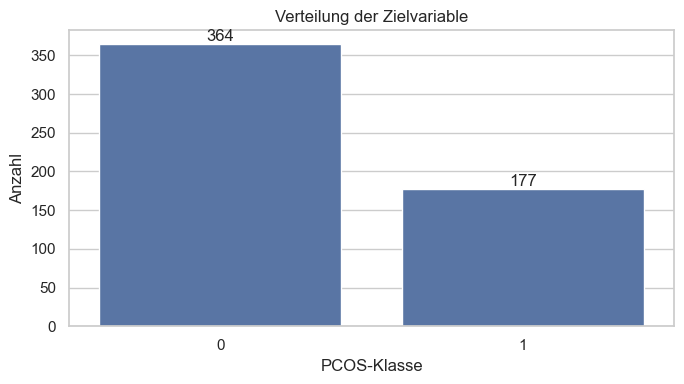

In [7]:
class_counts = df_model[TARGET].value_counts().sort_index()
class_pct = 100 * df_model[TARGET].value_counts(normalize=True).sort_index()
class_table = pd.DataFrame({'Anzahl': class_counts, 'Prozent': class_pct})
class_table.index = ['kein PCOS (0)', 'PCOS (1)']
display(class_table)

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df_model, x=TARGET, ax=ax, color=sns.color_palette('deep')[0])
ax.set_title('Verteilung der Zielvariable')
ax.set_xlabel('PCOS-Klasse')
ax.set_ylabel('Anzahl')
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

,fehlend_n,fehlend_pct
AMH_ng_mL,1,0.1848
Fast_food_YN,1,0.1848


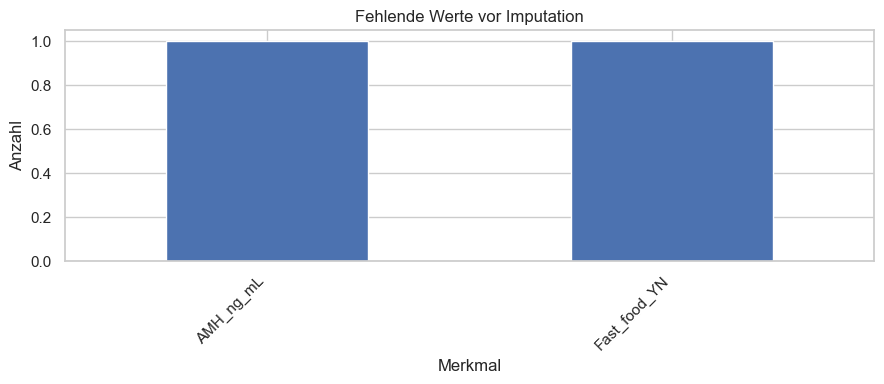

In [8]:
missing = df_model.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]

if missing.empty:
    print('Keine fehlenden Werte im Modellierungsdatensatz.')
else:
    display(pd.DataFrame({'fehlend_n': missing, 'fehlend_pct': 100 * missing / len(df_model)}))
    fig, ax = plt.subplots(figsize=(9, 4))
    missing.plot(kind='bar', ax=ax)
    ax.set_title('Fehlende Werte vor Imputation')
    ax.set_ylabel('Anzahl')
    ax.set_xlabel('Merkmal')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

In [9]:
# Deskriptive Statistik
numeric_cols = df_model.select_dtypes(include=[np.number]).columns.tolist()
feature_cols = [c for c in numeric_cols if c != TARGET]

descriptive_stats = (
    df_model[feature_cols]
    .describe()
    .rename_axis("Kennzahl", axis=0)
    .rename_axis("Feature", axis=1)
)

descriptive_stats.head(10)

Feature,Age_yrs,Weight_Kg,Height_Cm,BMI,Cycle_R_I,Cycle_length_days,FSH_mIU_mL,LH_mIU_mL,FSH_LH_ratio,Hip_inch,Waist_inch,Waist_Hip_ratio,TSH_mIU_L,AMH_ng_mL,PRG_ng_mL,RBS_mg_dl,Weight_gain_YN,Hair_growth_YN,Skin_darkening_YN,Hair_loss_YN,Pimples_YN,Fast_food_YN,Regular_exercise_YN,Endometrium_mm,Follicle_no_max,Avg_F_size_max_mm
Kennzahl,,,,,,,,,,,,,,,,,,,,,,,,,,
count,541.0000,541.0000,541.0000,541.0000,541.0000,541.0000,541.0000,541.0000,541.0000,541.0000,541.0000,541.0000,541.0000,540.0000,541.0000,541.0000,541.0000,541.0000,541.0000,541.0000,541.0000,540.0000,541.0000,541.0000,541.0000,541.0000
mean,31.4307,59.6372,156.4848,24.3113,2.5601,4.9409,14.6018,6.4699,6.9048,37.9926,33.8410,0.8919,2.9813,5.6242,0.6109,99.8359,0.3771,0.2736,0.3068,0.4529,0.4898,0.5148,0.2477,8.4759,7.4159,16.3998
std,5.4110,11.0283,6.0335,4.0564,0.9020,1.4920,217.0221,86.6733,60.6918,3.9679,3.5969,0.0463,3.7555,5.8816,3.8089,18.5593,0.4851,0.4462,0.4616,0.4982,0.5004,0.5002,0.4321,2.1654,4.5590,2.9116
min,20.0000,31.0000,137.0000,12.4179,2.0000,0.0000,0.2100,0.0200,0.0021,26.0000,24.0000,0.7556,0.0400,0.1000,0.0470,60.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,5.8000
25%,28.0000,52.0000,152.0000,21.6413,2.0000,4.0000,3.3000,1.0200,1.4162,36.0000,32.0000,0.8571,1.4800,2.0100,0.2500,92.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,7.0000,4.0000,15.0000
50%,31.0000,59.0000,156.0000,24.2382,2.0000,5.0000,4.8500,2.3000,2.1692,38.0000,34.0000,0.8947,2.2600,3.7000,0.3200,100.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,8.5000,7.0000,17.0000
75%,35.0000,65.0000,160.0000,26.6350,4.0000,5.0000,6.4100,3.6800,3.9592,40.0000,36.0000,0.9286,3.5700,6.9250,0.4500,107.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,9.8000,10.0000,19.0000
max,48.0000,108.0000,180.0000,38.9000,5.0000,12.0000,"5,052.0000","2,018.0000","1,372.8261",48.0000,47.0000,0.9792,65.0000,66.0000,85.0000,350.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,18.0000,22.0000,24.0000


Anzahl kontinuierlicher Merkmale: 16
Visualisierte Merkmale: ['Age_yrs', 'Weight_Kg', 'Height_Cm', 'BMI', 'Cycle_length_days', 'LH_mIU_mL', 'FSH_LH_ratio', 'Hip_inch', 'Waist_inch', 'Waist_Hip_ratio', 'TSH_mIU_L', 'AMH_ng_mL', 'RBS_mg_dl', 'Endometrium_mm', 'Follicle_no_max', 'Avg_F_size_max_mm']


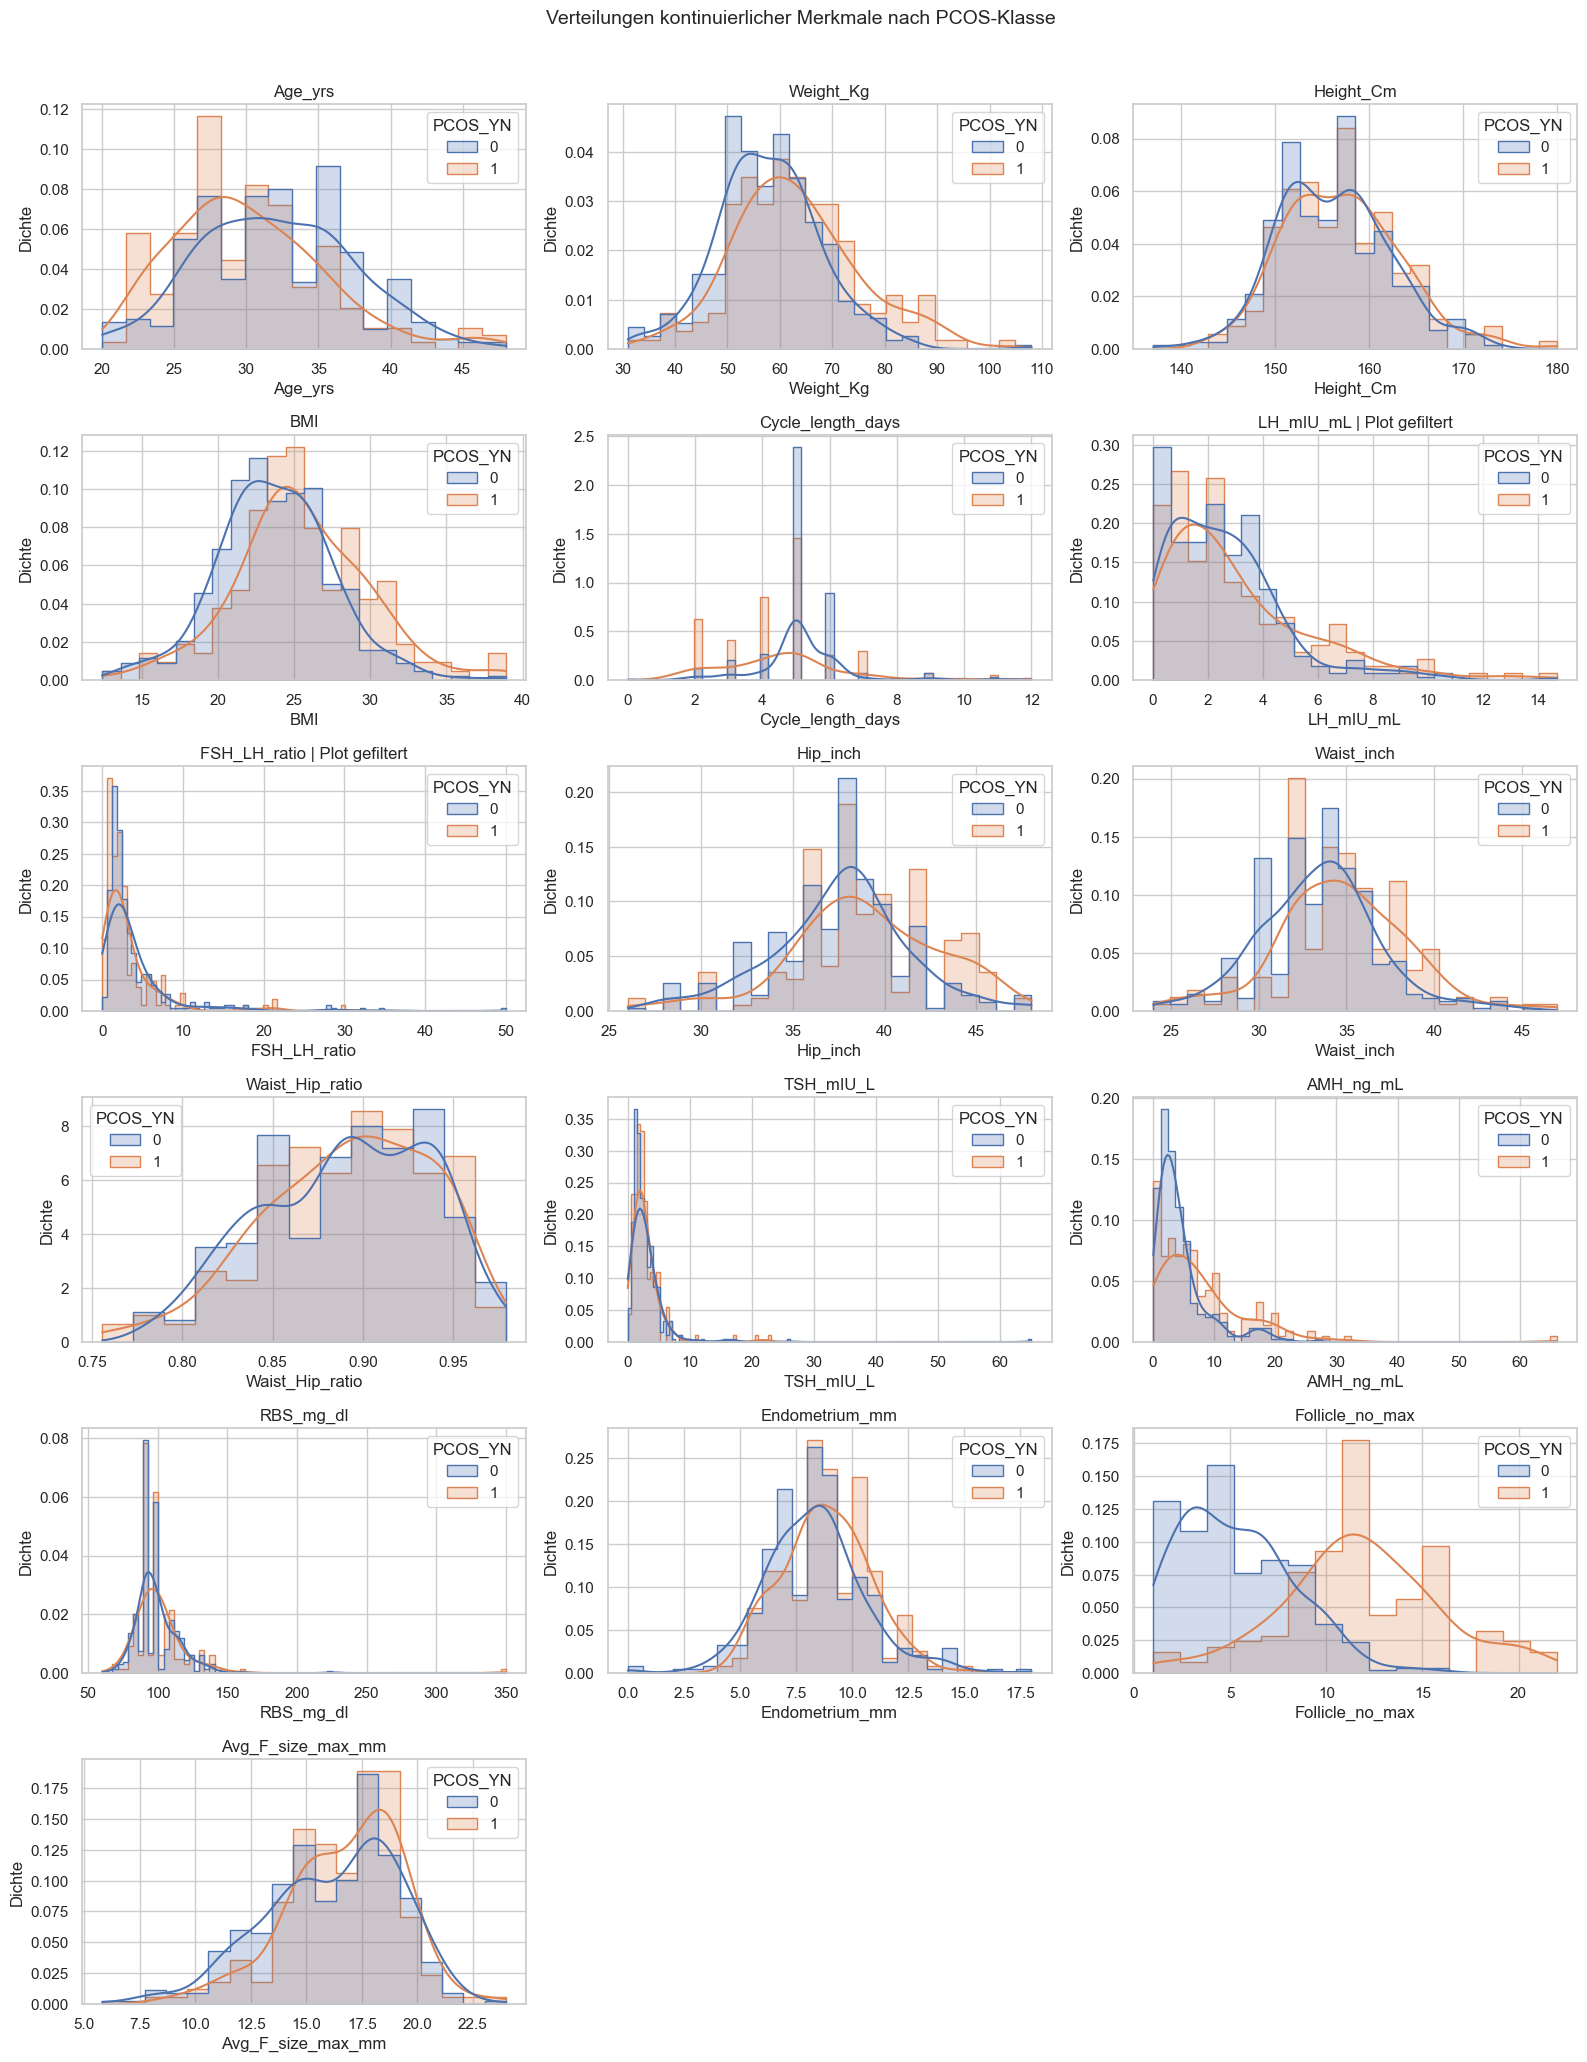

In [10]:
# Verteilungen aller kontinuierlichen Merkmale

EXCLUDE_FROM_VISUALIZATION = [
    "FSH_mIU_mL",
    "PRG_ng_mL",
]


continuous_candidates = [
    c for c in df_model.select_dtypes(include=[np.number]).columns
    if c != TARGET
    and c not in EXCLUDE_FROM_VISUALIZATION
    and df_model[c].nunique(dropna=True) > 5
    and df_model[c].notna().sum() > 1
]

PLOT_FILTERS = {
    # "Spaltenname": {"min": untere_grenze, "max": obere_grenze}

    "LH_mIU_mL": {"min": 0, "max": 100},
    "FSH_LH_ratio": {"min": 0, "max": 50},

    # Weitere Beispiele:
    # "AMH_ng_mL": {"min": 0, "max": 25},
}

print(f"Anzahl kontinuierlicher Merkmale: {len(continuous_candidates)}")
print("Visualisierte Merkmale:", continuous_candidates)

if len(continuous_candidates) == 0:
    print("Keine kontinuierlichen Merkmale für Histogramme gefunden.")
else:
    n_cols = 3
    n_rows = int(np.ceil(len(continuous_candidates) / n_cols))

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(16, 3.4 * n_rows)
    )

    axes = np.asarray(axes).reshape(-1)

    removed_values_report = []

    for ax, col in zip(axes, continuous_candidates):

        # Kopie nur für diese eine Visualisierung
        plot_data = df_model[[col, TARGET]].copy()

        before_n = len(plot_data)

        # Fehlende Werte entfernen
        plot_data = plot_data.dropna(subset=[col, TARGET])

        # Falls für diese Spalte manuelle Filter definiert wurden
        if col in PLOT_FILTERS:
            rules = PLOT_FILTERS[col]

            if "min" in rules:
                plot_data = plot_data[plot_data[col] >= rules["min"]]

            if "max" in rules:
                plot_data = plot_data[plot_data[col] <= rules["max"]]

        after_n = len(plot_data)
        removed_n = before_n - after_n

        if removed_n > 0:
            removed_values_report.append({
                "Feature": col,
                "entfernte_Werte_nur_fuer_Plot": removed_n,
                "verbleibende_Werte": after_n
            })

        sns.histplot(
            data=plot_data,
            x=col,
            hue=TARGET,
            kde=True,
            element="step",
            stat="density",
            common_norm=False,
            ax=ax
        )

        ax.set_title(col)
        ax.set_xlabel(col)
        ax.set_ylabel("Dichte")

        # Hinweis im Plot-Titel, falls Werte gefiltert wurden
        if col in PLOT_FILTERS:
            ax.set_title(f"{col} | Plot gefiltert")

    # Leere Subplots ausblenden
    for ax in axes[len(continuous_candidates):]:
        ax.axis("off")

    fig.suptitle(
        "Verteilungen kontinuierlicher Merkmale nach PCOS-Klasse",
        y=1.01,
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

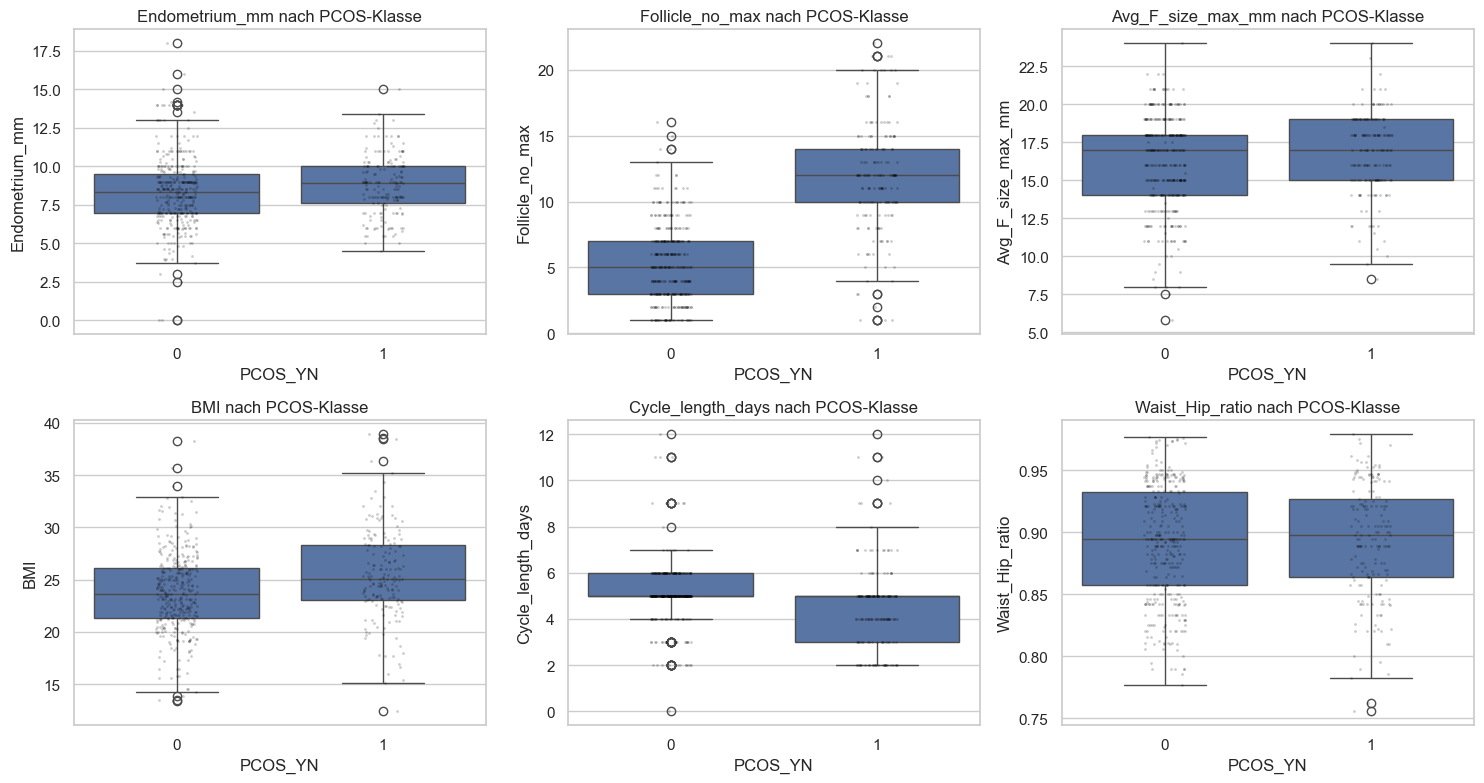

In [11]:
# Boxplots zentraler klinischer Merkmale
preferred_features = [
    'Endometrium_mm', 'Follicle_no_max', 'Avg_F_size_max_mm',
    'BMI', 'Cycle_length_days',
    'Waist_Hip_ratio',
]
plot_features = [c for c in preferred_features if c in df_model.columns]

n_cols = 3
n_rows = int(np.ceil(len(plot_features) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = np.asarray(axes).reshape(-1)
for ax, col in zip(axes, plot_features):
    sns.boxplot(data=df_model, x=TARGET, y=col, ax=ax)
    sns.stripplot(data=df_model, x=TARGET, y=col, color='black', alpha=0.20, size=2, ax=ax)
    ax.set_title(f'{col} nach PCOS-Klasse')
for ax in axes[len(plot_features):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

PCOS_YN,kein PCOS,PCOS
Fast_food_YN,0.3829,0.7853
Pimples_YN,0.3901,0.6949
Weight_gain_YN,0.2280,0.6836
Skin_darkening_YN,0.1538,0.6215
Hair_loss_YN,0.3929,0.5763
Hair_growth_YN,0.1291,0.5706
Regular_exercise_YN,0.2280,0.2881


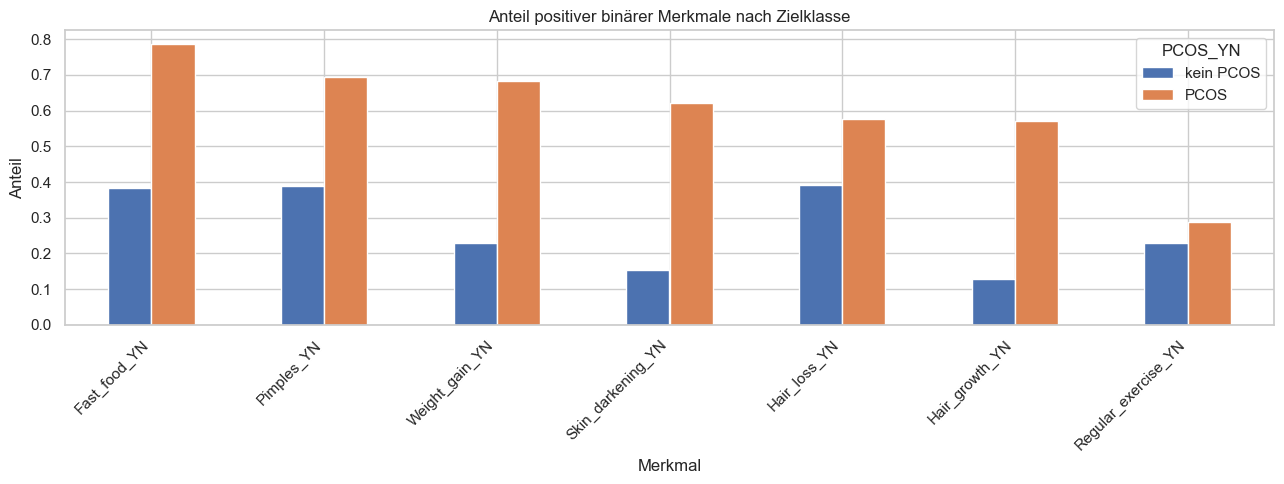

In [12]:
# Prävalenz binärer Symptome nach Zielklasse
binary_features = [
    c for c in df_model.columns
    if c != TARGET and set(df_model[c].dropna().unique()).issubset({0, 1})
]

if binary_features:
    prevalence = (
        df_model.groupby(TARGET)[binary_features]
        .mean()
        .T
        .rename(columns={0: 'kein PCOS', 1: 'PCOS'})
        .sort_values('PCOS', ascending=False)
    )
    display(prevalence)
    prevalence.plot(kind='bar', figsize=(13, 5))
    plt.title('Anteil positiver binärer Merkmale nach Zielklasse')
    plt.ylabel('Anteil')
    plt.xlabel('Merkmal')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print('Keine binären Merkmale erkannt.')

,Korrelation_mit_PCOS
Follicle_no_max,0.6672
Skin_darkening_YN,0.4757
Hair_growth_YN,0.4647
Weight_gain_YN,0.4410
Cycle_R_I,0.4016
Fast_food_YN,0.3779
Pimples_YN,0.2861
AMH_ng_mL,0.2639
Weight_Kg,0.2119
BMI,0.1995


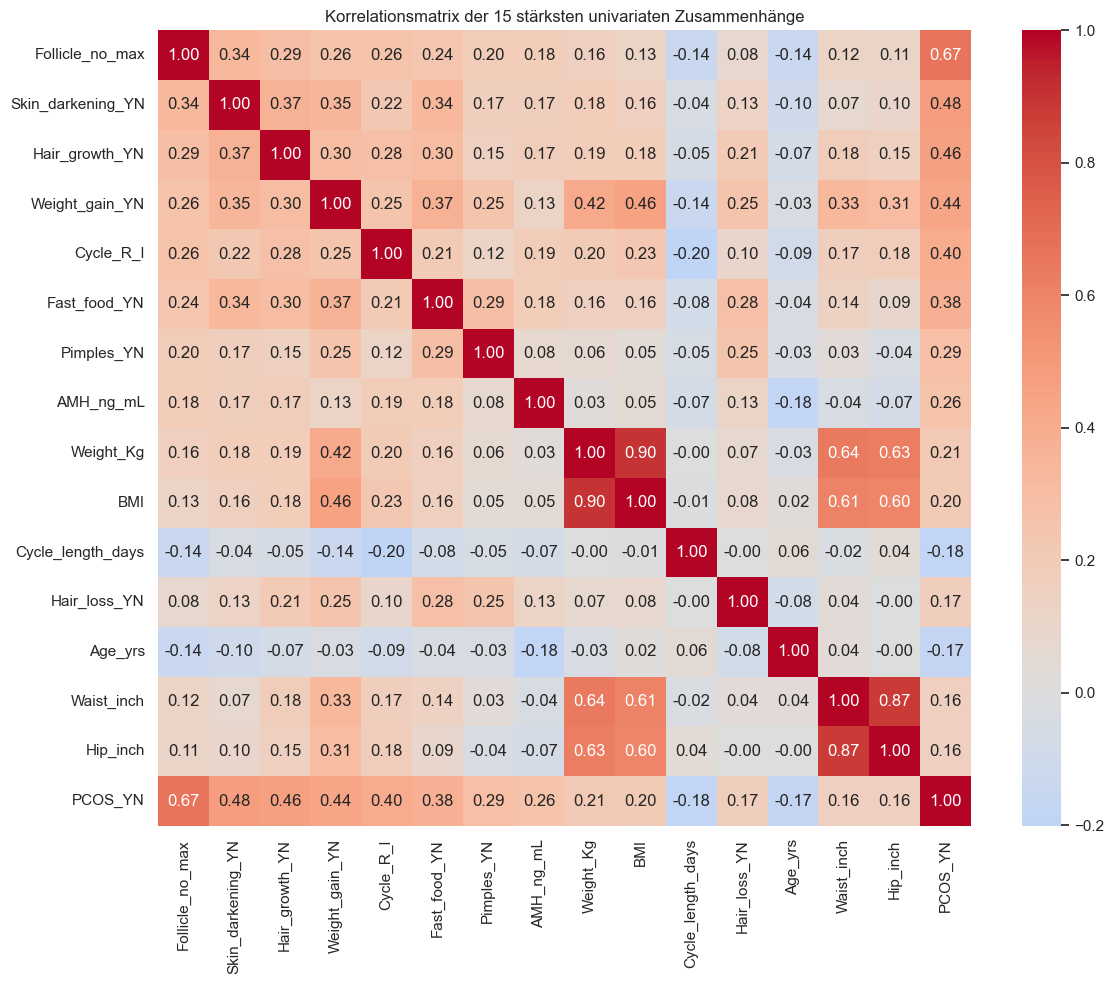

In [13]:
# Korrelationen mit der Zielvariable und Heatmap der am stärksten korrelierten Merkmale
corr = df_model.corr(numeric_only=True)
target_corr = corr[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False)
display(target_corr.to_frame('Korrelation_mit_PCOS'))

top_corr_features = target_corr.head(15).index.tolist() + [TARGET]
plt.figure(figsize=(12, 10))
sns.heatmap(df_model[top_corr_features].corr(), cmap='coolwarm', center=0, annot=True, fmt='.2f', square=False)
plt.title('Korrelationsmatrix der 15 stärksten univariaten Zusammenhänge')
plt.tight_layout()
plt.show()

**Interpretation der Korrelationsstärke:**  
Die Korrelationsmatrix zeigt lineare Zusammenhänge zwischen den numerischen Merkmalen des PCOS-Datensatzes. Für die Interpretation wird der Betrag des Korrelationskoeffizienten betrachtet: 

Werte mit \|r\| > 0,7 gelten als starke Korrelation

Werte zwischen 0,3 und 0,7 als moderate Korrelation und 

Werte unter 0,3 als schwache Korrelation. 

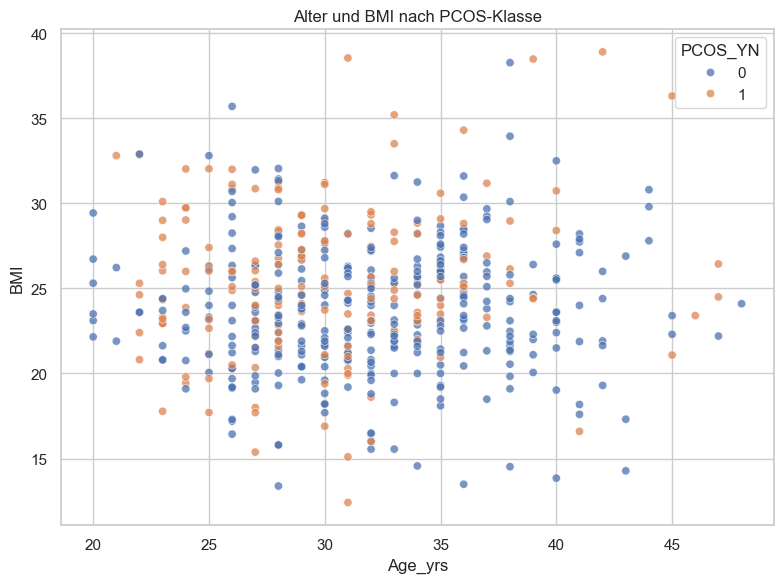

In [14]:
# Beispiel für mögliche Interaktion: Alter und BMI
if {'Age_yrs', 'BMI'}.issubset(df_model.columns):
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=df_model, x='Age_yrs', y='BMI', hue=TARGET, alpha=0.75)
    plt.title('Alter und BMI nach PCOS-Klasse')
    plt.tight_layout()
    plt.show()


#pairplot einfügen 

Für den Pairplot verwendete Merkmale:


,Feature
0,Age_yrs
1,BMI
2,AMH_ng_mL
3,Cycle_length_days
4,Follicle_no_max
5,Avg_F_size_max_mm


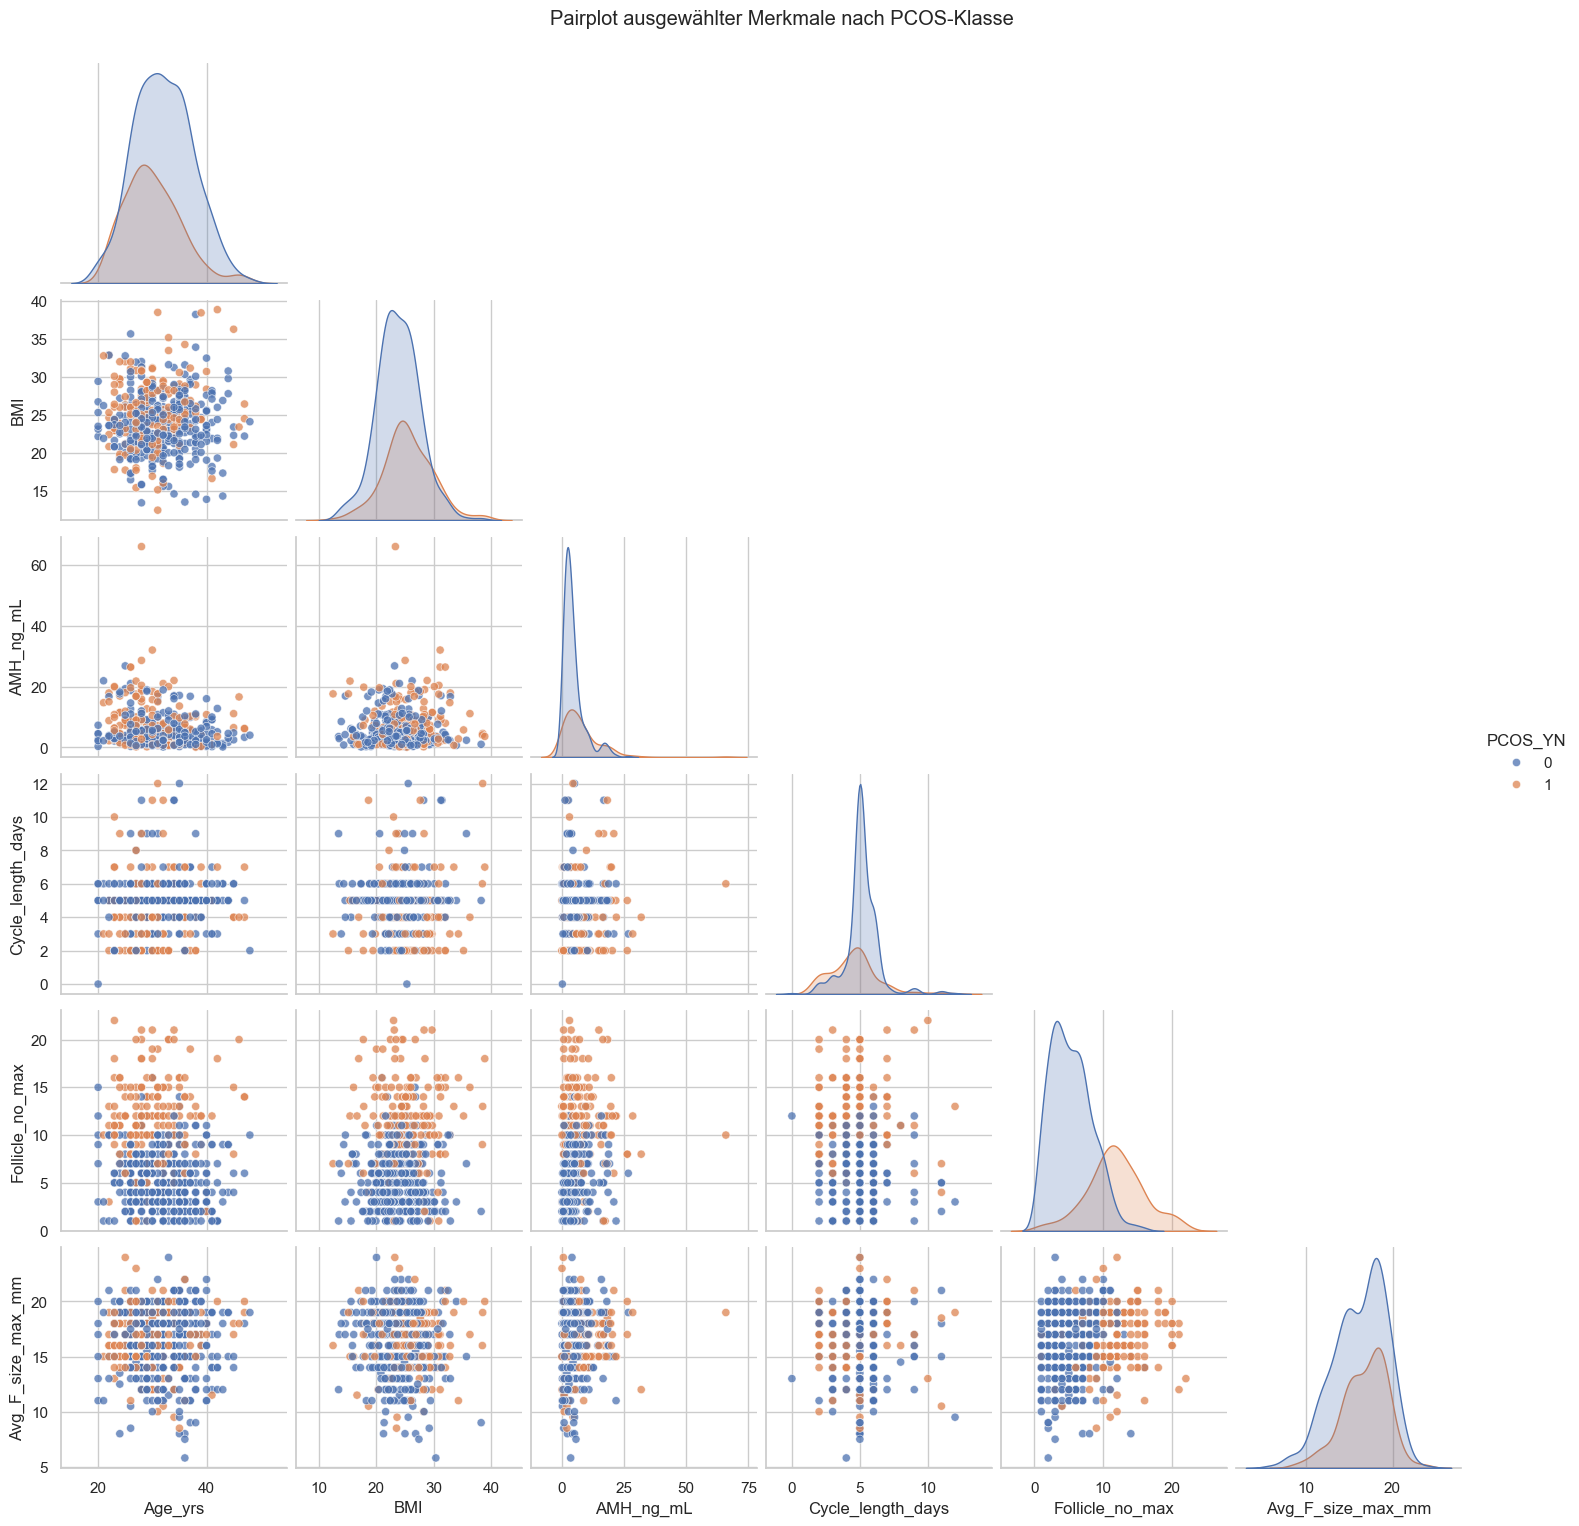

In [15]:
# Pairplot ausgewählter Merkmale nach PCOS-Klasse

pairplot_features = [
    "Age_yrs",
    "BMI",
    "AMH_ng_mL",
    "Cycle_length_days",
    "Follicle_no_max",
    "Avg_F_size_max_mm",
]

# Nur Merkmale verwenden, die tatsächlich im Modellierungsdatensatz existieren
pairplot_features = [c for c in pairplot_features if c in df_model.columns]

if TARGET not in df_model.columns:
    raise KeyError(f"TARGET {TARGET!r} ist nicht in df_model enthalten.")

if len(pairplot_features) < 2:
    print("Zu wenige vorhandene Features für einen sinnvollen Pairplot.")
    print("Vorhandene numerische Spalten:", df_model.select_dtypes(include=[np.number]).columns.tolist())
else:
    plot_data = df_model[pairplot_features + [TARGET]].dropna().copy()

    print("Für den Pairplot verwendete Merkmale:")
    display(pd.DataFrame({"Feature": pairplot_features}))

    sns.pairplot(
        data=plot_data,
        vars=pairplot_features,
        hue=TARGET,
        diag_kind="kde",
        corner=True,
        plot_kws={"alpha": 0.75, "s": 35},
    )

    plt.suptitle("Pairplot ausgewählter Merkmale nach PCOS-Klasse", y=1.02)
    plt.show()

### Univariate Statistik

Die folgenden Mann-Whitney-U-Tests vergleichen kontinuierliche Merkmale zwischen den beiden Klassen. Die p-Werte werden mit Benjamini-Hochberg für multiples Testen korrigiert. Diese Tests zeigen **Assoziationen**, keine Kausalität, und werden nicht als alleinige Feature-Selektion verwendet.

In [16]:
def benjamini_hochberg(p_values):
    p = np.asarray(p_values, dtype=float)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order]
    adjusted = ranked * n / np.arange(1, n + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    adjusted = np.clip(adjusted, 0, 1)
    result = np.empty(n)
    result[order] = adjusted
    return result

univariate_rows = []
for col in continuous_candidates:
    g0 = df_model.loc[df_model[TARGET] == 0, col].dropna()
    g1 = df_model.loc[df_model[TARGET] == 1, col].dropna()
    if len(g0) and len(g1):
        stat, p_value = mannwhitneyu(g0, g1, alternative='two-sided')
        univariate_rows.append({
            'Merkmal': col,
            'Median_0': g0.median(),
            'Median_1': g1.median(),
            'Median_Differenz_1_minus_0': g1.median() - g0.median(),
            'p_roh': p_value,
        })

univariate = pd.DataFrame(univariate_rows)
univariate['p_BH'] = benjamini_hochberg(univariate['p_roh'])
univariate = univariate.sort_values('p_BH')
display(univariate)

,Merkmal,Median_0,Median_1,Median_Differenz_1_minus_0,p_roh,p_BH
14,Follicle_no_max,5.0000,12.0000,7.0000,0.0000,0.0000
4,Cycle_length_days,5.0000,5.0000,0.0000,0.0000,0.0000
11,AMH_ng_mL,3.2000,5.9000,2.7000,0.0000,0.0000
1,Weight_Kg,58.0000,62.0000,4.0000,0.0000,0.0000
3,BMI,23.6000,25.1000,1.5000,0.0000,0.0000
0,Age_yrs,32.0000,29.0000,-3.0000,0.0000,0.0000
8,Waist_inch,34.0000,35.0000,1.0000,0.0000,0.0001
7,Hip_inch,38.0000,39.0000,1.0000,0.0002,0.0003
13,Endometrium_mm,8.3000,8.9000,0.6000,0.0045,0.0080
6,FSH_LH_ratio,2.3636,2.0360,-0.3276,0.0060,0.0096


## 2.6 Ausreißer erkennen und behandeln

Ausreißer werden zunächst mit der 1,5-IQR-Regel gezählt. Sie werden **nicht pauschal als Zeilen gelöscht**, weil extreme Labor- oder Ultraschallwerte medizinisch relevant sein können. Stattdessen werden kontinuierliche Merkmale innerhalb der Modell-Pipeline auf trainierte IQR-Grenzen begrenzt. Dadurch werden die Grenzwerte ausschließlich aus den jeweiligen Trainingsdaten gelernt und Datenleckage wird vermieden.

,IQR_Ausreisser
Cycle_length_days,77
AMH_ng_mL,52
FSH_LH_ratio,48
RBS_mg_dl,30
TSH_mIU_L,27
LH_mIU_mL,24
Hip_inch,21
Weight_Kg,18
Waist_inch,17
BMI,12


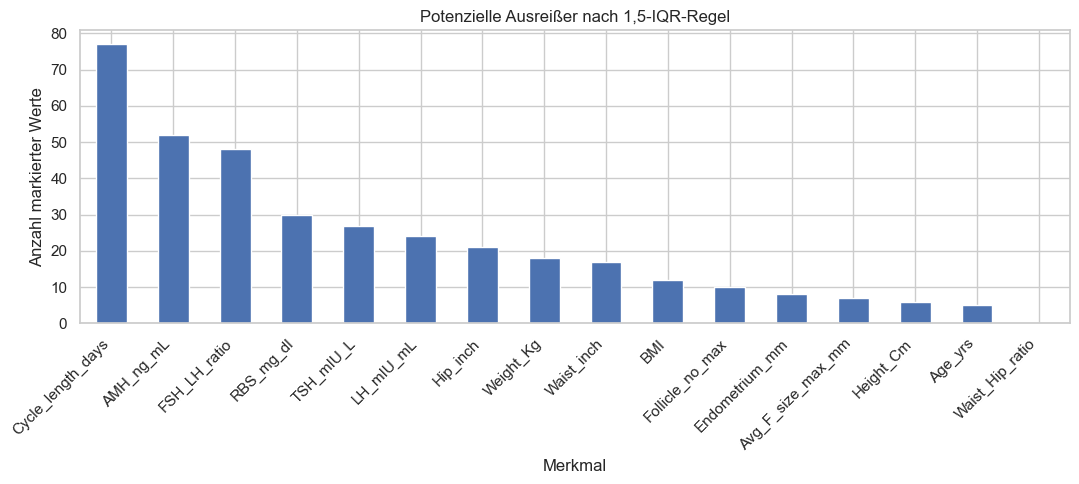

In [17]:
def iqr_outlier_count(series, factor=1.5):
    s = series.dropna()
    if s.empty:
        return 0
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    if iqr == 0:
        return 0
    lower, upper = q1 - factor * iqr, q3 + factor * iqr
    return int(((s < lower) | (s > upper)).sum())

outlier_counts = pd.Series(
    {c: iqr_outlier_count(df_model[c]) for c in continuous_candidates},
    name='IQR_Ausreisser'
).sort_values(ascending=False)

display(outlier_counts.to_frame())
plt.figure(figsize=(11, 5))
outlier_counts.plot(kind='bar')
plt.title('Potenzielle Ausreißer nach 1,5-IQR-Regel')
plt.ylabel('Anzahl markierter Werte')
plt.xlabel('Merkmal')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 2.7 Leakage-sichere Vorverarbeitung

- kontinuierliche Merkmale: Median-Imputation, IQR-Clipping; für die logistische Regression zusätzlich Standardisierung
- diskrete/binäre Merkmale: häufigster Wert und One-Hot-Encoding
- alle Transformationen befinden sich in einer `Pipeline` und werden in jedem CV-Fold neu gelernt

In [18]:
X = df_model.drop(columns=TARGET)
y = df_model[TARGET]

# Geringe Kardinalität wird als diskret/kategoriell behandelt.
discrete_features = [c for c in X.columns if X[c].nunique(dropna=True) <= 5]
continuous_features = [c for c in X.columns if c not in discrete_features]

print('Kontinuierliche Merkmale:', continuous_features)
print('Diskrete Merkmale:', discrete_features)

class IQRClipper(BaseEstimator, TransformerMixin):
    """Begrenzt Spalten auf Q1-factor*IQR und Q3+factor*IQR, gelernt nur auf Trainingsdaten."""
    def __init__(self, factor=1.5):
        self.factor = factor

    def fit(self, X, y=None):
        X_array = np.asarray(X, dtype=float)
        self.q1_ = np.nanpercentile(X_array, 25, axis=0)
        self.q3_ = np.nanpercentile(X_array, 75, axis=0)
        iqr = self.q3_ - self.q1_
        self.lower_ = np.where(iqr > 0, self.q1_ - self.factor * iqr, -np.inf)
        self.upper_ = np.where(iqr > 0, self.q3_ + self.factor * iqr, np.inf)
        self.n_features_in_ = X_array.shape[1]
        return self

    def transform(self, X):
        X_array = np.asarray(X, dtype=float)
        return np.clip(X_array, self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return np.asarray([f'x{i}' for i in range(self.n_features_in_)], dtype=object)
        return np.asarray(input_features, dtype=object)


def make_preprocessor(scale_continuous=False):
    continuous_steps = [
        ('imputer', SimpleImputer(strategy='median')),
        ('iqr_clipper', IQRClipper(factor=1.5)),
    ]
    if scale_continuous:
        continuous_steps.append(('scaler', StandardScaler()))

    continuous_pipe = Pipeline(continuous_steps)
    discrete_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False)),
    ])

    return ColumnTransformer(
        transformers=[
            ('continuous', continuous_pipe, continuous_features),
            ('discrete', discrete_pipe, discrete_features),
        ],
        remainder='drop',
        verbose_feature_names_out=False,
    )

Kontinuierliche Merkmale: ['Age_yrs', 'Weight_Kg', 'Height_Cm', 'BMI', 'Cycle_length_days', 'FSH_mIU_mL', 'LH_mIU_mL', 'FSH_LH_ratio', 'Hip_inch', 'Waist_inch', 'Waist_Hip_ratio', 'TSH_mIU_L', 'AMH_ng_mL', 'PRG_ng_mL', 'RBS_mg_dl', 'Endometrium_mm', 'Follicle_no_max', 'Avg_F_size_max_mm']
Diskrete Merkmale: ['Cycle_R_I', 'Weight_gain_YN', 'Hair_growth_YN', 'Skin_darkening_YN', 'Hair_loss_YN', 'Pimples_YN', 'Fast_food_YN', 'Regular_exercise_YN']


# 3. Modellierung und Evaluation

## 3.1 Datenaufteilung und Kreuzvalidierung

20 % der Daten werden als unangetasteter Testdatensatz zurückgehalten. Die Aufteilung ist stratifiziert, damit beide Klassen in ähnlicher Relation in Training und Test vertreten sind. Hyperparameter werden ausschließlich auf den Trainingsdaten mittels 5-facher stratifizierter Kreuzvalidierung optimiert.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

split_table = pd.DataFrame({
    'Datensatz': ['Training', 'Test'],
    'n': [len(y_train), len(y_test)],
    'PCOS_Anteil': [y_train.mean(), y_test.mean()],
})
display(split_table)

,Datensatz,n,PCOS_Anteil
0,Training,432,0.3264
1,Test,109,0.3303


## 3.2 Baseline und Klassenungleichgewicht

Ein `DummyClassifier` dient als Mindestvergleich. Für Logistische Regression, Decision Tree und Random Forest wird `class_weight="balanced"` verwendet. Bei XGBoost wird `scale_pos_weight = n_negativ / n_positiv` aus dem Trainingssatz berechnet.

In [20]:
dummy = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', DummyClassifier(strategy='prior', random_state=RANDOM_STATE)),
])
dummy.fit(X_train, y_train)
dummy_prob = dummy.predict_proba(X_test)[:, 1]
print('Dummy ROC-AUC:', roc_auc_score(y_test, dummy_prob))

negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / positive_count
print('scale_pos_weight für XGBoost:', round(scale_pos_weight, 4))

Dummy ROC-AUC: 0.5
scale_pos_weight für XGBoost: 2.0638


## 3.3 Modelle und Hyperparameter-Optimierung

Die Suchräume sind bewusst begrenzt: Der Datensatz ist klein, und eine sehr große Suche würde das Risiko erhöhen, die Kreuzvalidierungsfalten zu überoptimieren. Logistische Regression und Decision Tree werden per Grid Search, Random Forest und XGBoost per reproduzierbarer Randomized Search abgestimmt. Optimierungsmetrik ist ROC-AUC.

In [21]:
model_specs = {
    'Logistic Regression': {
        'pipeline': Pipeline([
            ('prep', make_preprocessor(scale_continuous=True)),
            ('model', LogisticRegression(
                solver='liblinear',
                max_iter=3000,
                class_weight='balanced',
                random_state=RANDOM_STATE,
            )),
        ]),
        'search': 'grid',
        'params': {
            'model__C': [0.1, 1.0, 10.0],
            'model__penalty': ['l1', 'l2'],
        },
    },
    'Decision Tree': {
        'pipeline': Pipeline([
            ('prep', make_preprocessor(scale_continuous=False)),
            ('model', DecisionTreeClassifier(
                class_weight='balanced',
                random_state=RANDOM_STATE,
            )),
        ]),
        'search': 'grid',
        'params': {
            'model__criterion': ['gini', 'entropy'],
            'model__max_depth': [3, 5, 7],
            'model__min_samples_leaf': [1, 5],
        },
    },
    'Random Forest': {
        'pipeline': Pipeline([
            ('prep', make_preprocessor(scale_continuous=False)),
            ('model', RandomForestClassifier(
                class_weight='balanced',
                random_state=RANDOM_STATE,
                n_jobs=1,
            )),
        ]),
        'search': 'random',
        'n_iter': 6,
        'params': {
            'model__n_estimators': [150, 300],
            'model__max_depth': [None, 5, 8],
            'model__min_samples_leaf': [1, 3, 6],
            'model__max_features': ['sqrt', 0.7],
        },
    },
    'XGBoost': {
        'pipeline': Pipeline([
            ('prep', make_preprocessor(scale_continuous=False)),
            ('model', XGBClassifier(
                objective='binary:logistic',
                eval_metric='logloss',
                tree_method='hist',
                scale_pos_weight=scale_pos_weight,
                random_state=RANDOM_STATE,
                n_jobs=1,
            )),
        ]),
        'search': 'random',
        'n_iter': 6,
        'params': {
            'model__n_estimators': [100, 200],
            'model__max_depth': [2, 3, 4],
            'model__learning_rate': [0.03, 0.10],
            'model__subsample': [0.80, 1.00],
            'model__colsample_bytree': [0.80, 1.00],
            'model__min_child_weight': [1, 3],

            'model__reg_lambda': [1, 5],
        },
    },
}

In [22]:
searches = {}
best_estimators = {}

for name, spec in model_specs.items():
    print(f'Optimiere: {name}')
    common_args = dict(
        estimator=spec['pipeline'],
        scoring='roc_auc',
        cv=cv,
        n_jobs=1,
        return_train_score=True,
        refit=True,
        verbose=0,
    )

    if spec['search'] == 'grid':
        search = GridSearchCV(param_grid=spec['params'], **common_args)
    else:
        search = RandomizedSearchCV(
            param_distributions=spec['params'],
            n_iter=spec['n_iter'],
            random_state=RANDOM_STATE,
            **common_args,
        )

    search.fit(X_train, y_train)
    searches[name] = search
    best_estimators[name] = search.best_estimator_
    print(f'  beste CV ROC-AUC: {search.best_score_:.4f}')
    print(f'  beste Parameter: {search.best_params_}')

Optimiere: Logistic Regression
  beste CV ROC-AUC: 0.9497
  beste Parameter: {'model__C': 1.0, 'model__penalty': 'l1'}
Optimiere: Decision Tree
  beste CV ROC-AUC: 0.8973
  beste Parameter: {'model__criterion': 'entropy', 'model__max_depth': 3, 'model__min_samples_leaf': 5}
Optimiere: Random Forest
  beste CV ROC-AUC: 0.9595
  beste Parameter: {'model__n_estimators': 300, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 5}
Optimiere: XGBoost
  beste CV ROC-AUC: 0.9518
  beste Parameter: {'model__subsample': 0.8, 'model__reg_lambda': 1, 'model__n_estimators': 100, 'model__min_child_weight': 3, 'model__max_depth': 4, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0}


### 3.3.1 Visualisierung der besten Modelle nach Hyperparameter-Optimierung

In [23]:
# Visualisierung der optimierten Einzelmodelle

def get_feature_names_from_pipeline(pipeline, X):
    """
    Extrahiert Feature-Namen nach der Vorverarbeitung.
    Falls das nicht funktioniert, werden die ursprünglichen X-Spalten verwendet.
    """
    prep = pipeline.named_steps["prep"]

    try:
        feature_names = prep.get_feature_names_out()
        feature_names = [str(name).split("__")[-1] for name in feature_names]
    except Exception:
        feature_names = X.columns.tolist()

    return feature_names

,Feature,Koeffizient
16,Follicle_no_max,2.0769
22,Hair_growth_YN_1.0,1.8061
23,Skin_darkening_YN_1.0,1.3529
18,Cycle_R_I_2.0,-1.3457
21,Weight_gain_YN_1.0,0.9789
25,Pimples_YN_1.0,0.6844
14,RBS_mg_dl,0.3631
4,Cycle_length_days,-0.3302
0,Age_yrs,-0.2991
11,TSH_mIU_L,0.2858


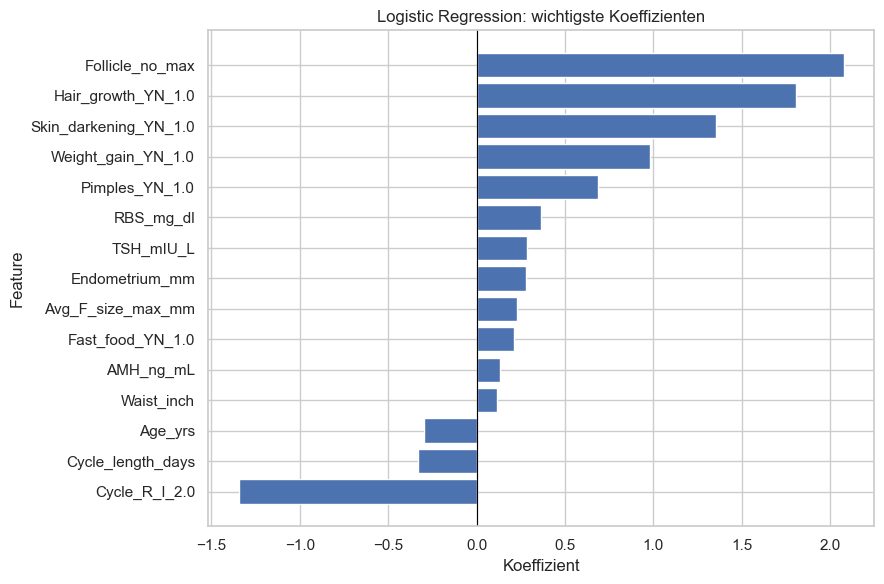

In [24]:
# Logistic Regression

model_name = "Logistic Regression"

if model_name in best_estimators:
    logreg_pipeline = best_estimators[model_name]
    logreg_model = logreg_pipeline.named_steps["model"]

    feature_names = get_feature_names_from_pipeline(logreg_pipeline, X_train)
    coefficients = logreg_model.coef_[0]

    if len(feature_names) != len(coefficients):
        print("Achtung: Anzahl Feature-Namen passt nicht zur Anzahl Koeffizienten.")
        print("Feature-Namen:", len(feature_names))
        print("Koeffizienten:", len(coefficients))
    else:
        coef_df = pd.DataFrame({
            "Feature": feature_names,
            "Koeffizient": coefficients,
            "Abs_Koeffizient": np.abs(coefficients)
        }).sort_values("Abs_Koeffizient", ascending=False).head(15)

        display(coef_df[["Feature", "Koeffizient"]])

        plot_df = coef_df.sort_values("Koeffizient")

        plt.figure(figsize=(9, 6))
        plt.barh(plot_df["Feature"], plot_df["Koeffizient"])
        plt.axvline(0, color="black", linewidth=0.8)
        plt.title("Logistic Regression: wichtigste Koeffizienten")
        plt.xlabel("Koeffizient")
        plt.ylabel("Feature")
        plt.tight_layout()
        plt.show()
else:
    print("Logistic Regression wurde nicht in best_estimators gefunden.")

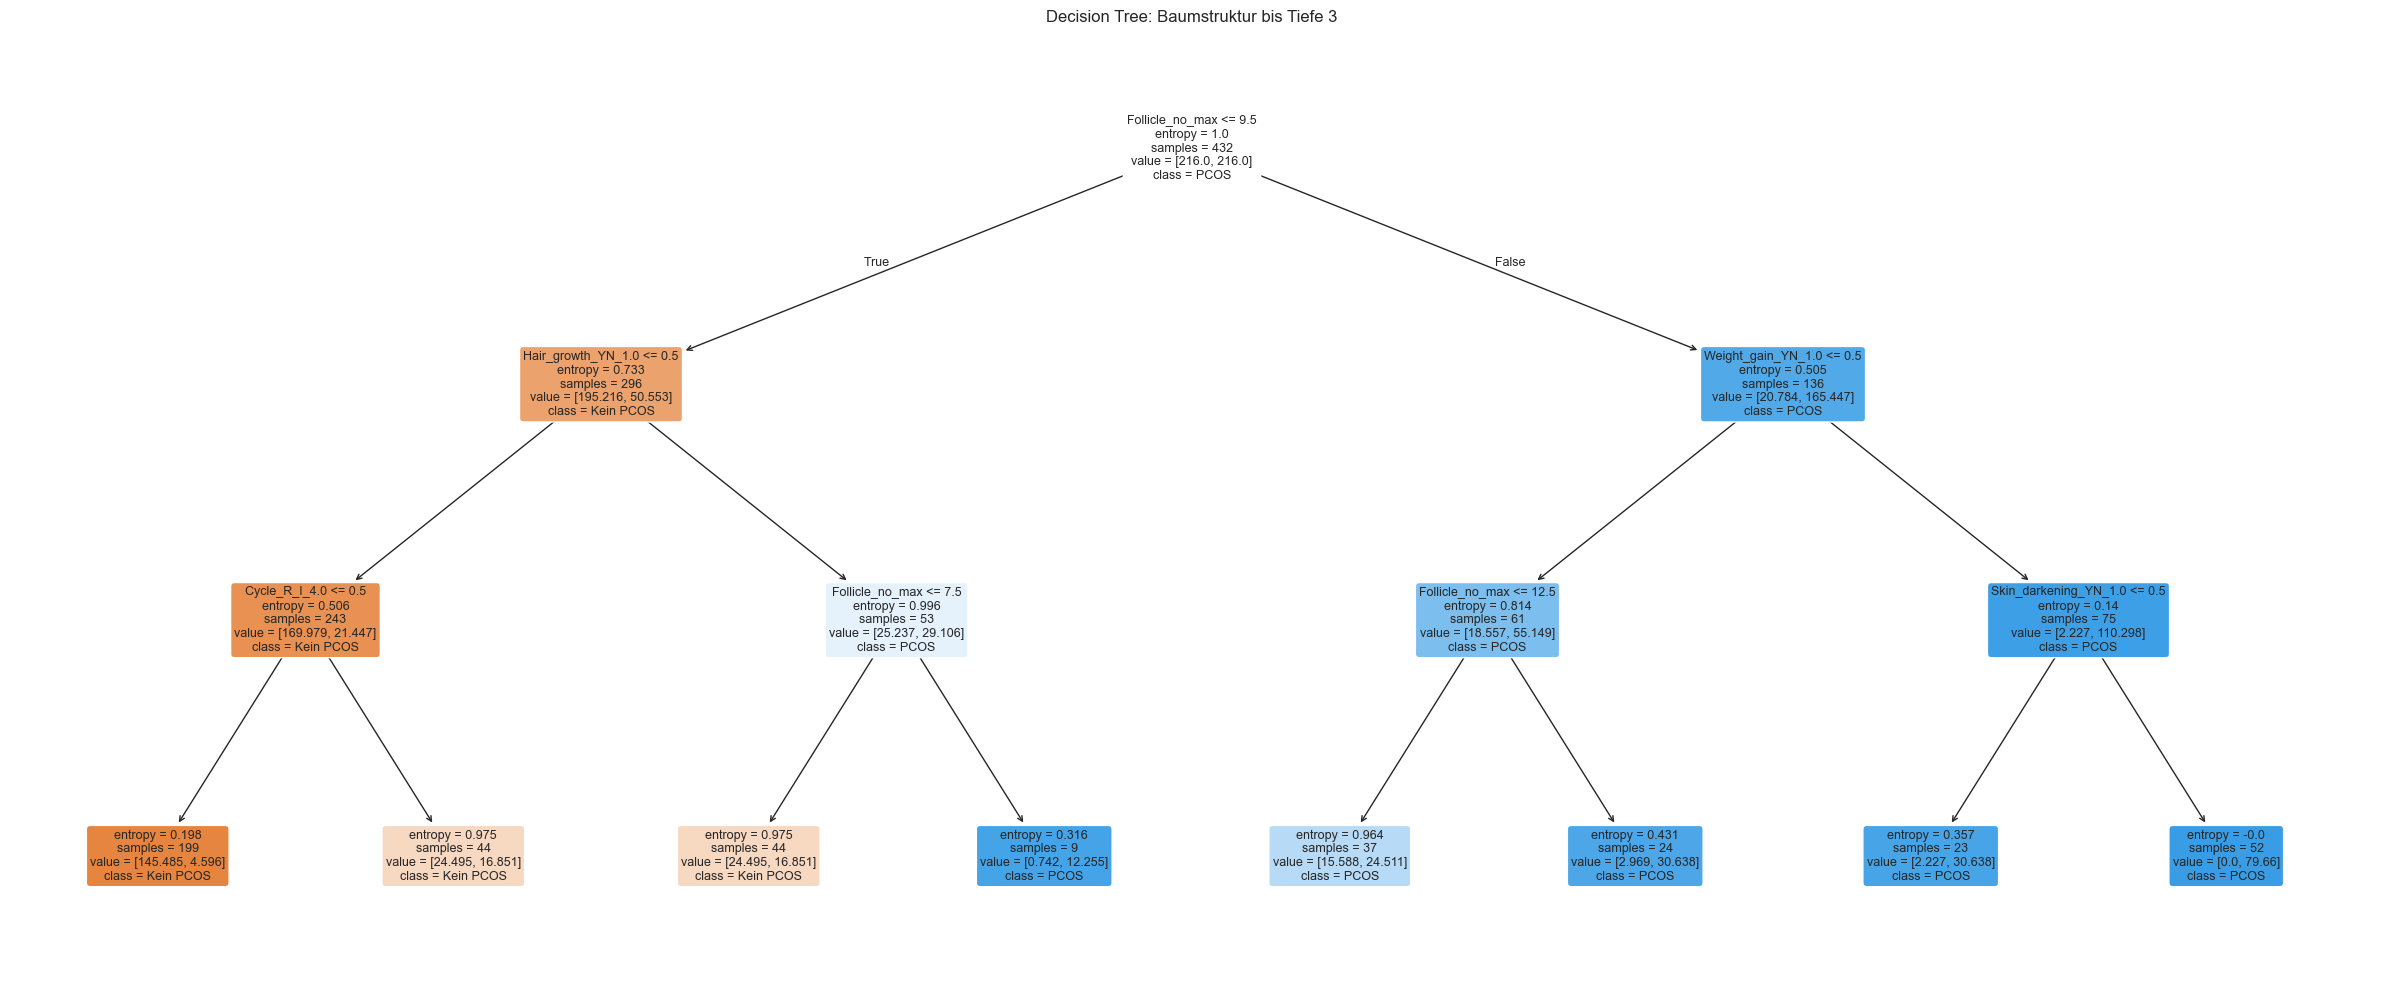

In [25]:
# Decision Tree: Baumstruktur visualisieren

model_name = "Decision Tree"

if model_name in best_estimators:
    tree_pipeline = best_estimators[model_name]
    tree_model = tree_pipeline.named_steps["model"]

    feature_names = get_feature_names_from_pipeline(tree_pipeline, X_train)

    plt.figure(figsize=(24, 10))
    plot_tree(
        tree_model,
        feature_names=feature_names,
        class_names=["Kein PCOS", "PCOS"],
        filled=True,
        rounded=True,
        max_depth=3,
        fontsize=9
    )

    plt.title("Decision Tree: Baumstruktur bis Tiefe 3")
    plt.tight_layout()
    plt.show()
else:
    print("Decision Tree wurde nicht in best_estimators gefunden.")

,Feature,Importance
16,Follicle_no_max,0.3030
23,Skin_darkening_YN_1.0,0.0845
21,Weight_gain_YN_1.0,0.0728
22,Hair_growth_YN_1.0,0.0725
12,AMH_ng_mL,0.0466
4,Cycle_length_days,0.0362
26,Fast_food_YN_1.0,0.0339
19,Cycle_R_I_4.0,0.0279
18,Cycle_R_I_2.0,0.0273
3,BMI,0.0235


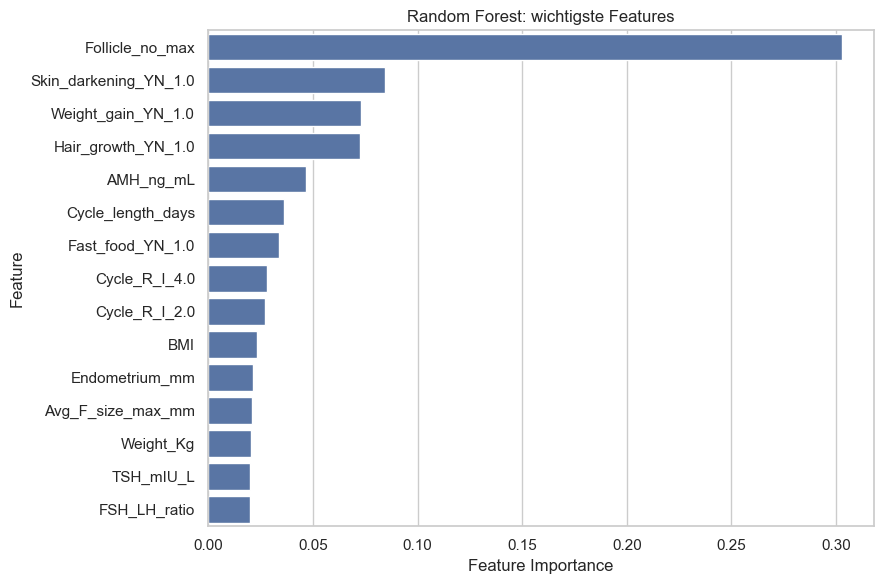

In [26]:
# Random Forest: Feature Importance

model_name = "Random Forest"

if model_name in best_estimators:
    rf_pipeline = best_estimators[model_name]
    rf_model = rf_pipeline.named_steps["model"]

    feature_names = get_feature_names_from_pipeline(rf_pipeline, X_train)
    importances = rf_model.feature_importances_

    if len(feature_names) != len(importances):
        print("Achtung: Anzahl Feature-Namen passt nicht zur Anzahl Importances.")
        print("Feature-Namen:", len(feature_names))
        print("Importances:", len(importances))
    else:
        rf_importance_df = pd.DataFrame({
            "Feature": feature_names,
            "Importance": importances
        }).sort_values("Importance", ascending=False).head(15)

        display(rf_importance_df)

        plt.figure(figsize=(9, 6))
        sns.barplot(
            data=rf_importance_df,
            x="Importance",
            y="Feature"
        )
        plt.title("Random Forest: wichtigste Features")
        plt.xlabel("Feature Importance")
        plt.ylabel("Feature")
        plt.tight_layout()
        plt.show()

,Feature,Importance
16,Follicle_no_max,0.1919
18,Cycle_R_I_2.0,0.0749
22,Hair_growth_YN_1.0,0.0606
23,Skin_darkening_YN_1.0,0.0555
21,Weight_gain_YN_1.0,0.0540
26,Fast_food_YN_1.0,0.0511
4,Cycle_length_days,0.0448
27,Regular_exercise_YN_1.0,0.0423
12,AMH_ng_mL,0.0377
7,FSH_LH_ratio,0.0319


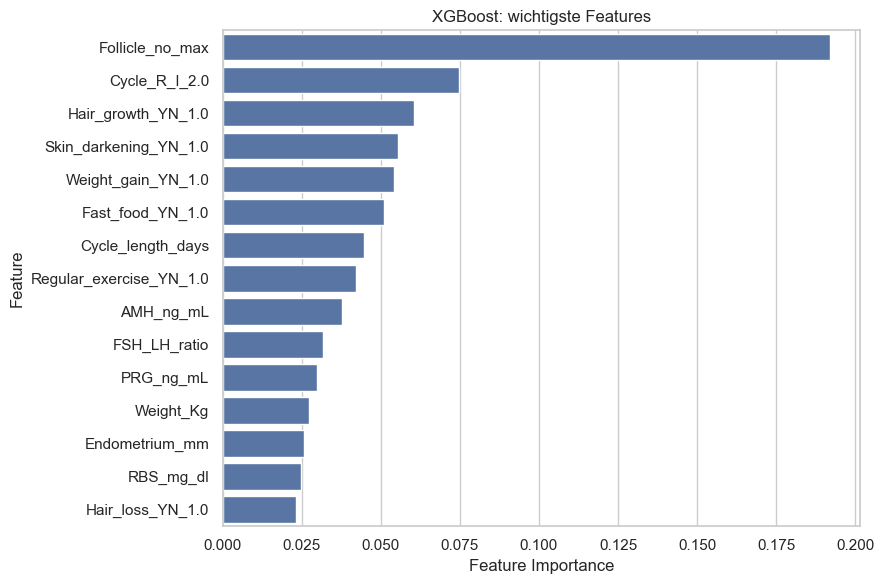

In [27]:
# XGBoost

model_name = "XGBoost"

if model_name in best_estimators:
    xgb_pipeline = best_estimators[model_name]
    xgb_model = xgb_pipeline.named_steps["model"]

    feature_names = get_feature_names_from_pipeline(xgb_pipeline, X_train)
    importances = xgb_model.feature_importances_

    if len(feature_names) != len(importances):
        print("Achtung: Anzahl Feature-Namen passt nicht zur Anzahl Importances.")
        print("Feature-Namen:", len(feature_names))
        print("Importances:", len(importances))
    else:
        xgb_importance_df = pd.DataFrame({
            "Feature": feature_names,
            "Importance": importances
        }).sort_values("Importance", ascending=False).head(15)

        display(xgb_importance_df)

        plt.figure(figsize=(9, 6))
        sns.barplot(
            data=xgb_importance_df,
            x="Importance",
            y="Feature"
        )
        plt.title("XGBoost: wichtigste Features")
        plt.xlabel("Feature Importance")
        plt.ylabel("Feature")
        plt.tight_layout()
        plt.show()
else:
    print("XGBoost wurde nicht in best_estimators gefunden.")

## 3.4 Evaluation mit problemorientierten Metriken

In [28]:
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return tn / (tn + fp) if (tn + fp) else np.nan


def evaluate_classifier(name, estimator, X_train, y_train, X_test, y_test, cv_search):
    train_prob = estimator.predict_proba(X_train)[:, 1]
    test_prob = estimator.predict_proba(X_test)[:, 1]
    train_pred = (train_prob >= 0.5).astype(int)
    test_pred = (test_prob >= 0.5).astype(int)

    best_index = cv_search.best_index_
    cv_train_auc = cv_search.cv_results_['mean_train_score'][best_index]
    cv_valid_auc = cv_search.best_score_

    return {
        'Modell': name,
        'CV_Train_ROC_AUC': cv_train_auc,
        'CV_ROC_AUC': cv_valid_auc,
        'CV_Gap': cv_train_auc - cv_valid_auc,
        'Train_ROC_AUC': roc_auc_score(y_train, train_prob),
        'Test_ROC_AUC': roc_auc_score(y_test, test_prob),
        'Test_PR_AUC': average_precision_score(y_test, test_prob),
        'Accuracy': accuracy_score(y_test, test_pred),
        'Precision': precision_score(y_test, test_pred, zero_division=0),
        'Recall': recall_score(y_test, test_pred, zero_division=0),
        'Specificity': specificity_score(y_test, test_pred),
        'F1': f1_score(y_test, test_pred, zero_division=0),
        'Brier': brier_score_loss(y_test, test_prob),
        'Best_Params': json.dumps(cv_search.best_params_, ensure_ascii=False),
    }

result_rows = [
    evaluate_classifier(name, estimator, X_train, y_train, X_test, y_test, searches[name])
    for name, estimator in best_estimators.items()
]
results_df = pd.DataFrame(result_rows).set_index('Modell').sort_values('CV_ROC_AUC', ascending=False)
display(results_df)

best_model_name = results_df['CV_ROC_AUC'].idxmax()
best_model = best_estimators[best_model_name]
print(f'Finale Modellauswahl anhand der Trainings-CV: {best_model_name}')

,CV_Train_ROC_AUC,CV_ROC_AUC,CV_Gap,Train_ROC_AUC,Test_ROC_AUC,Test_PR_AUC,Accuracy,Precision,Recall,Specificity,F1,Brier,Best_Params
Modell,,,,,,,,,,,,,
Random Forest,0.9996,0.9595,0.0401,0.9983,0.9547,0.9416,0.9266,0.9667,0.8056,0.9863,0.8788,0.0872,"{""model__n_estimators"": 300, ""model__min_sampl..."
XGBoost,0.9970,0.9518,0.0452,0.9964,0.9486,0.9378,0.9174,0.8857,0.8611,0.9452,0.8732,0.0729,"{""model__subsample"": 0.8, ""model__reg_lambda"":..."
Logistic Regression,0.9721,0.9497,0.0224,0.9699,0.9326,0.9182,0.8716,0.7750,0.8611,0.8767,0.8158,0.0884,"{""model__C"": 1.0, ""model__penalty"": ""l1""}"
Decision Tree,0.9463,0.8973,0.0490,0.9412,0.9422,0.9169,0.8807,0.7949,0.8611,0.8904,0.8267,0.0837,"{""model__criterion"": ""entropy"", ""model__max_de..."


Finale Modellauswahl anhand der Trainings-CV: Random Forest


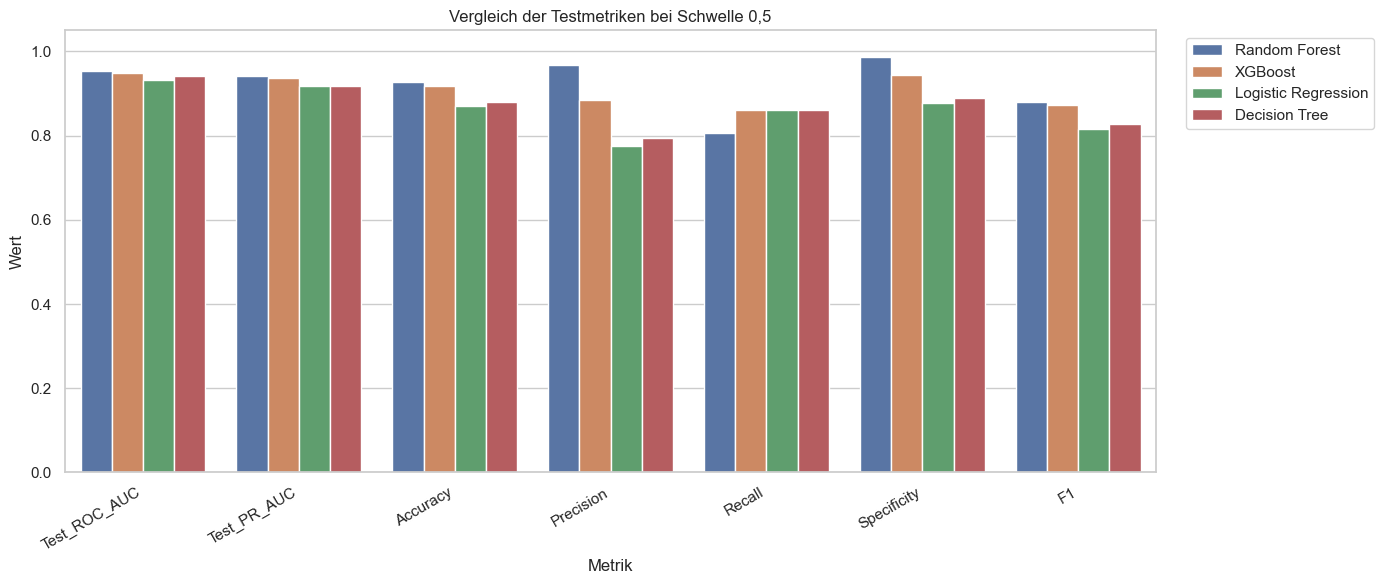

In [29]:
# Metrikvergleich
metrics_to_plot = ['Test_ROC_AUC', 'Test_PR_AUC', 'Accuracy', 'Precision', 'Recall', 'Specificity', 'F1']
plot_df = results_df[metrics_to_plot].reset_index().melt(id_vars='Modell', var_name='Metrik', value_name='Wert')

plt.figure(figsize=(14, 6))
sns.barplot(data=plot_df, x='Metrik', y='Wert', hue='Modell')
plt.ylim(0, 1.05)
plt.title('Vergleich der Testmetriken bei Schwelle 0,5')
plt.xticks(rotation=30, ha='right')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

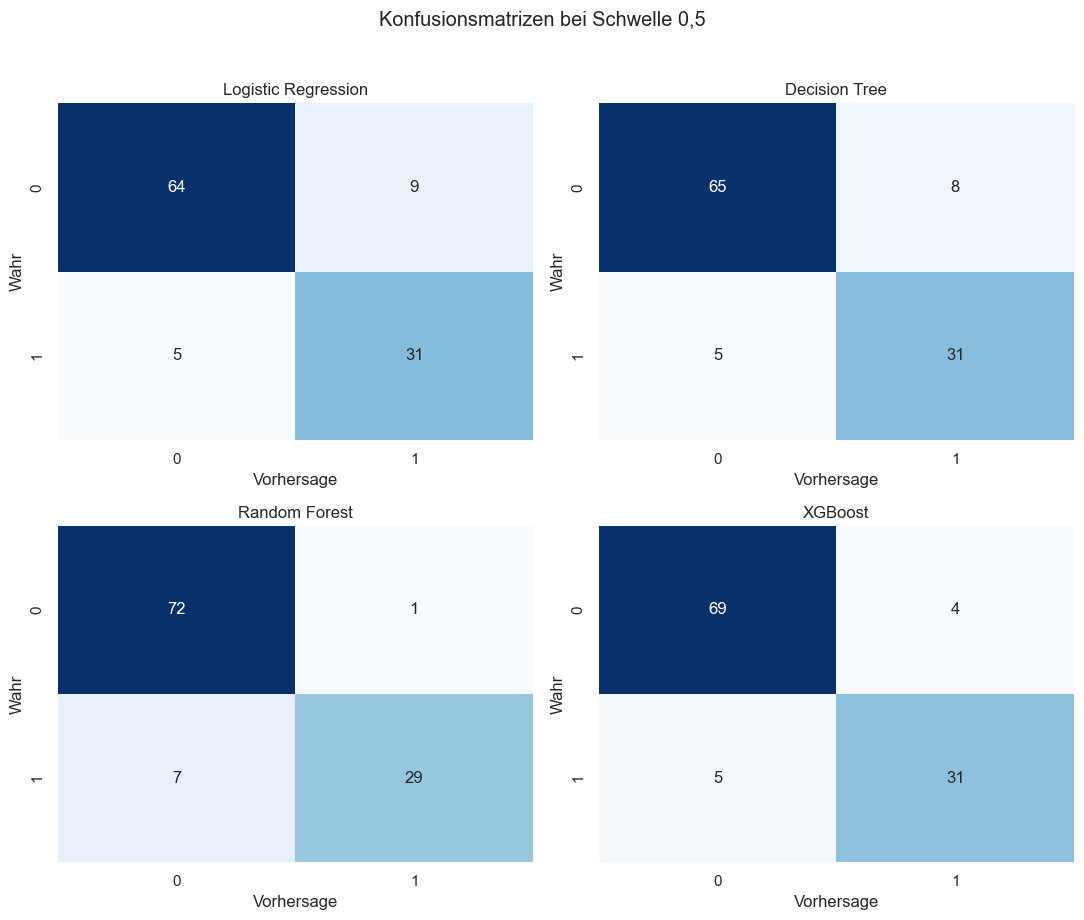

In [30]:
# Konfusionsmatrizen aller Modelle
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, estimator) in zip(axes.ravel(), best_estimators.items()):
    pred = estimator.predict(X_test)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Vorhersage')
    ax.set_ylabel('Wahr')
plt.suptitle('Konfusionsmatrizen bei Schwelle 0,5', y=1.02)
plt.tight_layout()
plt.show()

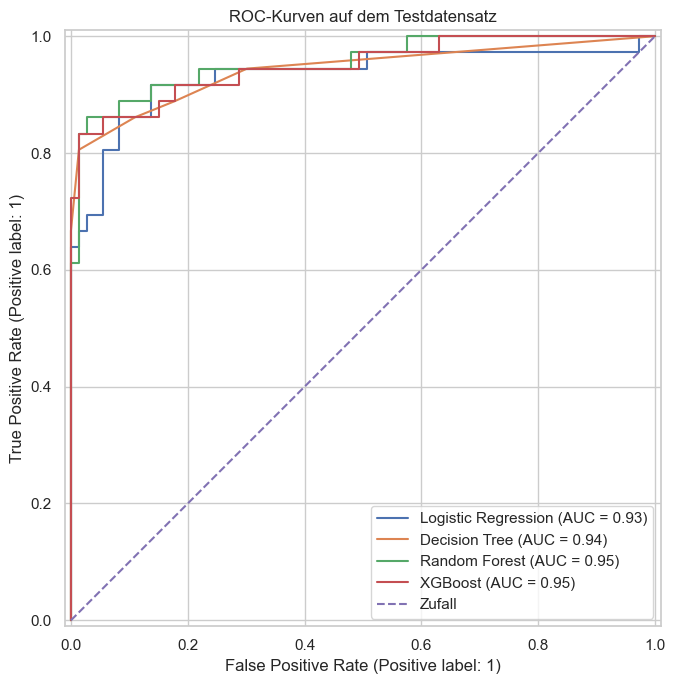

In [31]:
# ROC-Kurven
fig, ax = plt.subplots(figsize=(8, 7))
for name, estimator in best_estimators.items():
    RocCurveDisplay.from_estimator(estimator, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle='--', label='Zufall')
ax.set_title('ROC-Kurven auf dem Testdatensatz')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 3.5 Overfitting/Underfitting prüfen

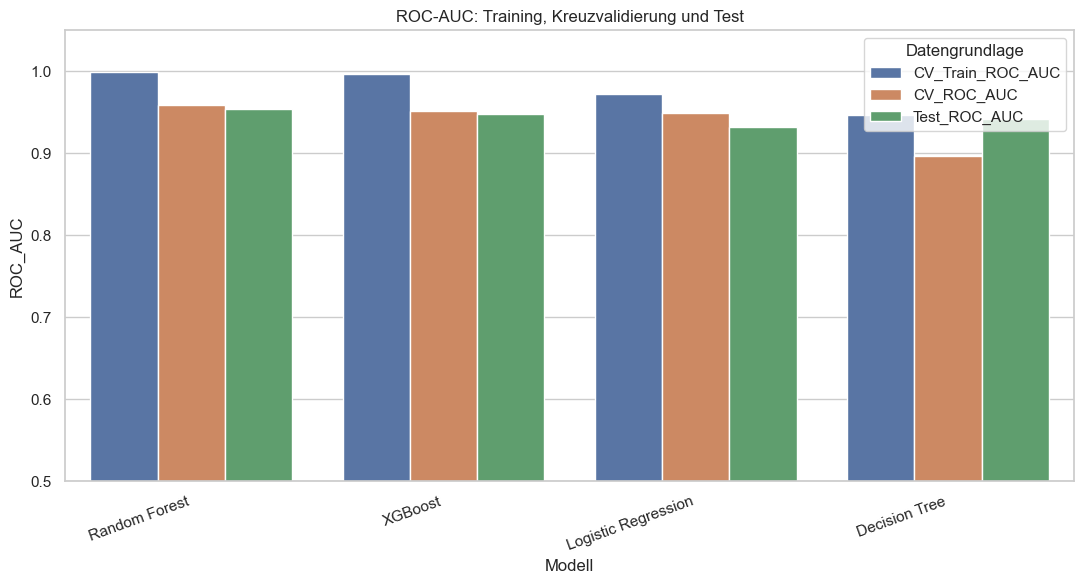

,CV_Train_ROC_AUC,CV_ROC_AUC,CV_Gap,Train_ROC_AUC,Test_ROC_AUC
Modell,,,,,
Random Forest,0.9996,0.9595,0.0401,0.9983,0.9547
XGBoost,0.9970,0.9518,0.0452,0.9964,0.9486
Logistic Regression,0.9721,0.9497,0.0224,0.9699,0.9326
Decision Tree,0.9463,0.8973,0.0490,0.9412,0.9422


In [32]:
# CV-Train vs. CV-Validierung und Test
auc_gap_plot = results_df[['CV_Train_ROC_AUC', 'CV_ROC_AUC', 'Test_ROC_AUC']].reset_index().melt(
    id_vars='Modell', var_name='Datengrundlage', value_name='ROC_AUC'
)
plt.figure(figsize=(11, 6))
sns.barplot(data=auc_gap_plot, x='Modell', y='ROC_AUC', hue='Datengrundlage')
plt.ylim(0.5, 1.05)
plt.title('ROC-AUC: Training, Kreuzvalidierung und Test')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

display(results_df[['CV_Train_ROC_AUC', 'CV_ROC_AUC', 'CV_Gap', 'Train_ROC_AUC', 'Test_ROC_AUC']])

# 4. Interpretation und Kommunikation der Ergebnisse

## 4.1 Modellvergleich und Reflexion

In [33]:
# Automatisch erzeugte Ergebniszusammenfassung
best_row = results_df.loc[best_model_name]
print(f'Nach Trainings-CV wurde {best_model_name} ausgewählt.')
print(f"CV ROC-AUC: {best_row['CV_ROC_AUC']:.3f}")
print(f"Test ROC-AUC: {best_row['Test_ROC_AUC']:.3f}")
print(f"Test Recall bei 0,5: {best_row['Recall']:.3f}")
print(f"Test Precision bei 0,5: {best_row['Precision']:.3f}")
print(f"Test F1 bei 0,5: {best_row['F1']:.3f}")
print(f"CV-Train/Validierungs-Gap: {best_row['CV_Gap']:.3f}")

if best_row['CV_Gap'] > 0.08:
    print('Kritischer Hinweis: Das CV-Gap deutet auf mögliches Overfitting hin.')
else:
    print('Das CV-Gap ist begrenzt; dennoch bleibt externe Validierung notwendig.')

Nach Trainings-CV wurde Random Forest ausgewählt.
CV ROC-AUC: 0.959
Test ROC-AUC: 0.955
Test Recall bei 0,5: 0.806
Test Precision bei 0,5: 0.967
Test F1 bei 0,5: 0.879
CV-Train/Validierungs-Gap: 0.040
Das CV-Gap ist begrenzt; dennoch bleibt externe Validierung notwendig.


## 4.2 Modellinterpretation: Feature Importance

,Merkmal,Wichtigkeit
16,Follicle_no_max,0.3030
23,Skin_darkening_YN_1.0,0.0845
21,Weight_gain_YN_1.0,0.0728
22,Hair_growth_YN_1.0,0.0725
12,AMH_ng_mL,0.0466
4,Cycle_length_days,0.0362
26,Fast_food_YN_1.0,0.0339
19,Cycle_R_I_4.0,0.0279
18,Cycle_R_I_2.0,0.0273
3,BMI,0.0235


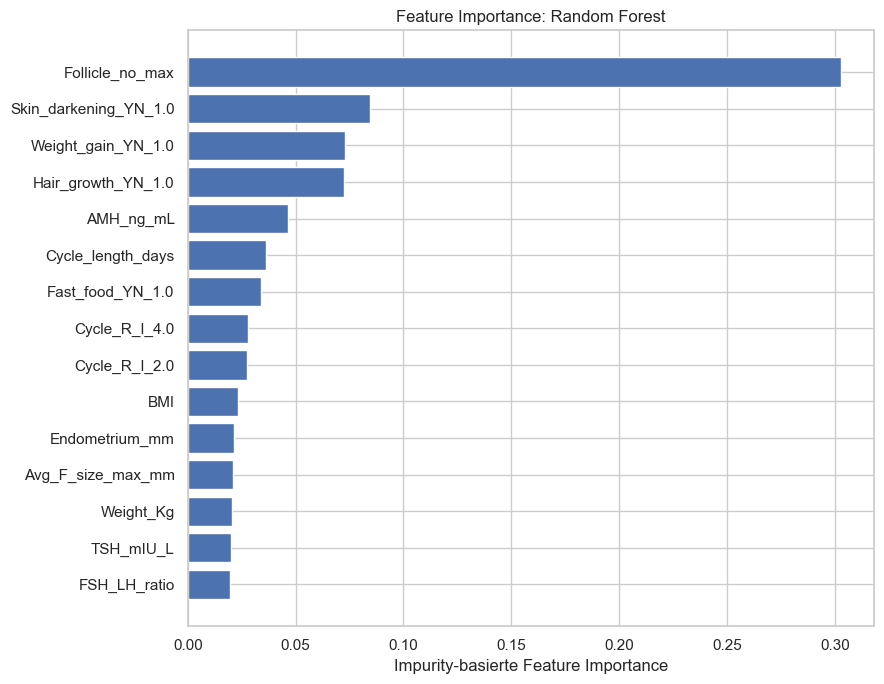

In [34]:
# Feature Importance des anhand der Trainings-CV ausgewählten Modells
# Für Baum-Ensembles wird die eingebaute Importance des transformierten Merkmalsraums genutzt.
# Für die logistische Regression wird der Betrag der standardisierten Koeffizienten verwendet.
selected_prep = best_model.named_steps['prep']
selected_model = best_model.named_steps['model']
selected_feature_names = selected_prep.get_feature_names_out()

if hasattr(selected_model, 'feature_importances_'):
    importance_values = selected_model.feature_importances_
    importance_label = 'Impurity-basierte Feature Importance'
elif hasattr(selected_model, 'coef_'):
    importance_values = np.abs(selected_model.coef_.ravel())
    importance_label = 'Betrag des standardisierten Koeffizienten'
else:
    raise AttributeError('Das ausgewählte Modell bietet keine direkte Feature Importance.')

importance_df = pd.DataFrame({
    'Merkmal': selected_feature_names,
    'Wichtigkeit': importance_values,
}).sort_values('Wichtigkeit', ascending=False)

display(importance_df.head(25))

top_importance = importance_df.head(15).sort_values('Wichtigkeit')
plt.figure(figsize=(9, 7))
plt.barh(top_importance['Merkmal'], top_importance['Wichtigkeit'])
plt.xlabel(importance_label)
plt.title(f'Feature Importance: {best_model_name}')
plt.tight_layout()
plt.show()